Codigo generado por: https://claude.ai/new

API de Gemini: <TU_GEMINI_API_KEY>

#ALGORITMO GENÉTICO Y TEORÍA DE JUEGOS

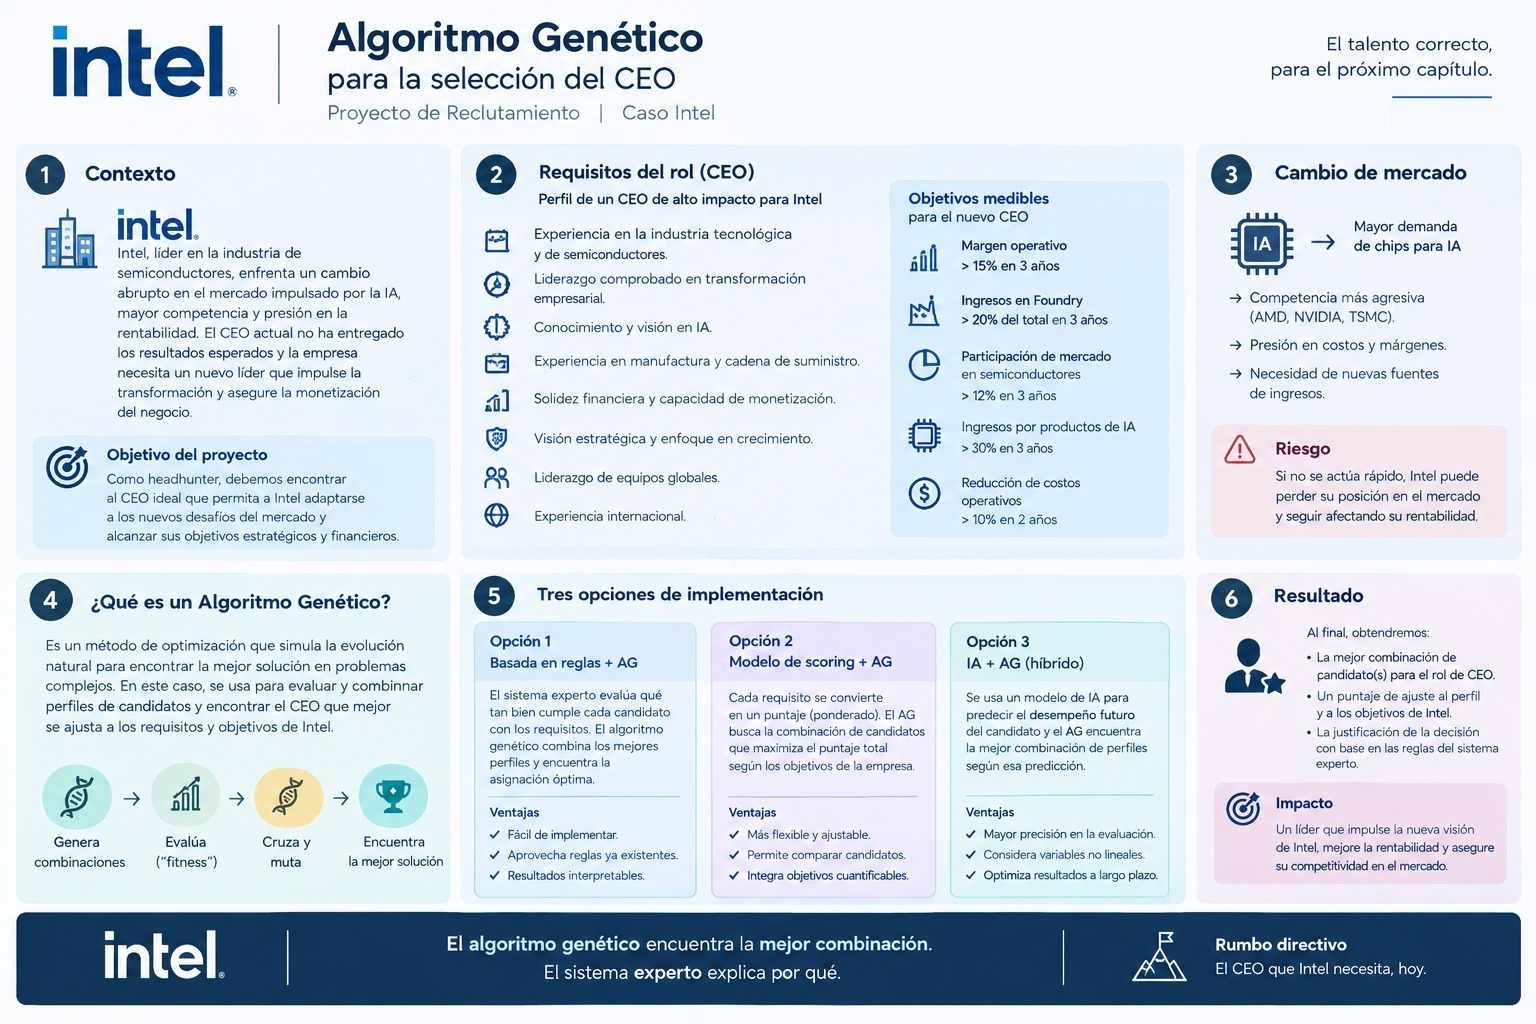

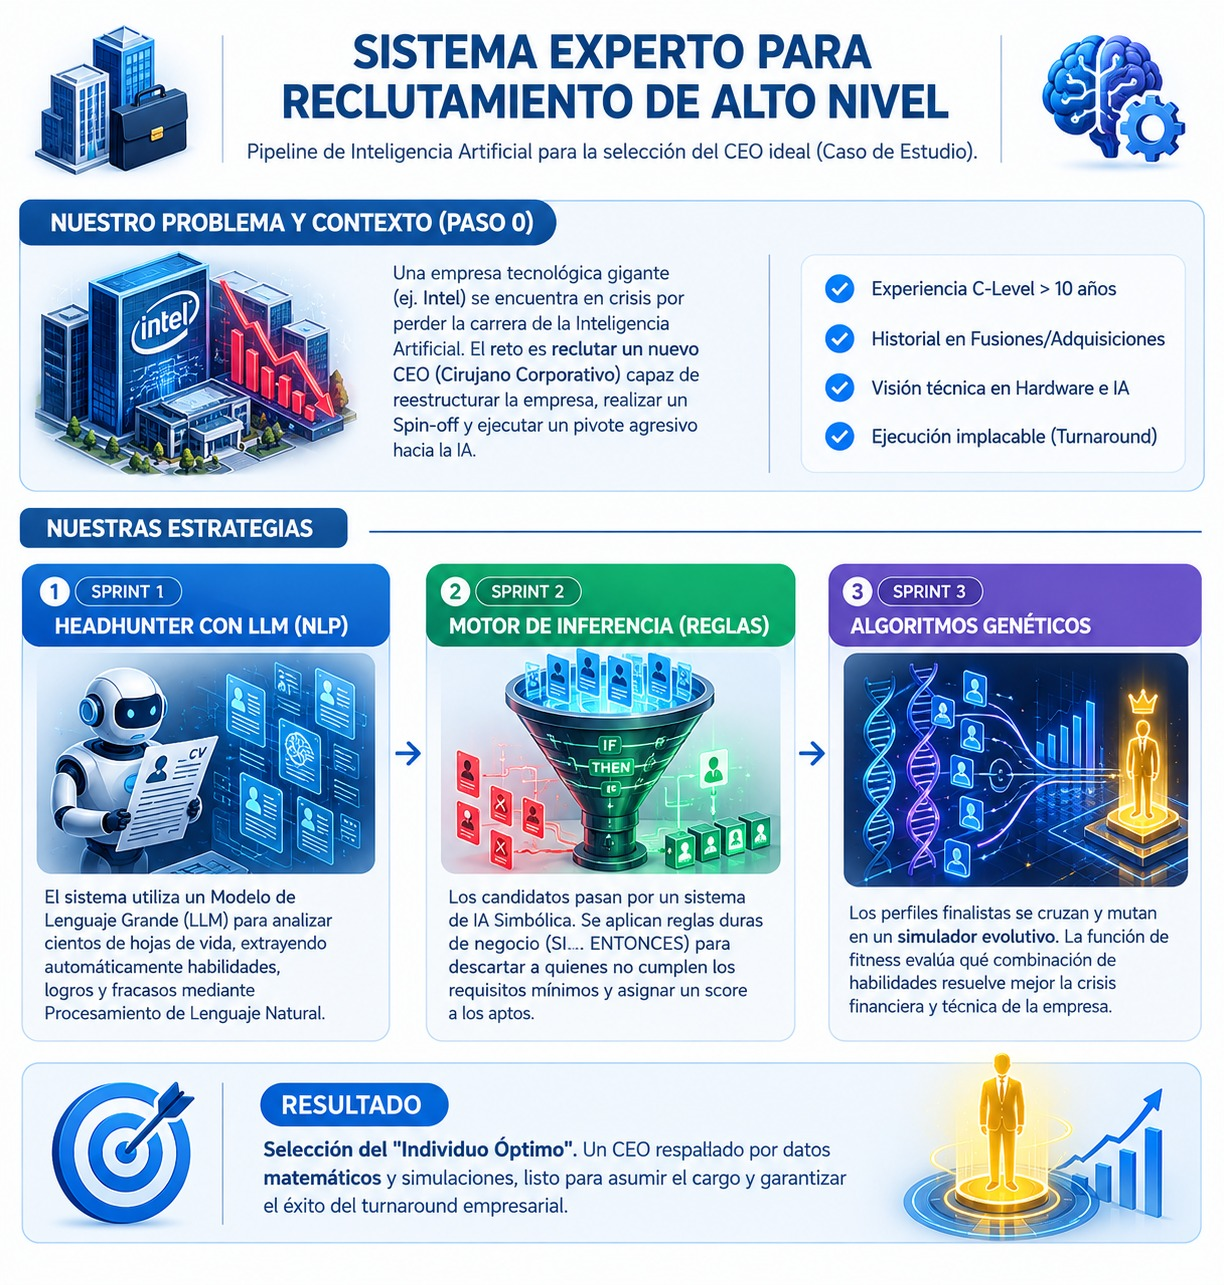

---
# VERSIÓN 2 — Pipeline completo con Paso 0 (LLM externo) y algoritmos corregidos

Las celdas anteriores son la **versión 1** del Sprint 3. Esta versión 2 conserva la idea y la corrige en dos puntos:

1. **Paso 0 real.** Antes, el tipo de crisis se detectaba con palabras clave (`obtener_configuracion_crisis`). Ahora un **LLM externo (Gemini u OpenAI, por API)** analiza a Intel, a su CEO actual, el legado del CEO anterior y el mercado. El LLM devuelve un **JSON** con la estrategia de reclutamiento, los requisitos rígidos y los pesos de cada criterio. Ese JSON configura todo el resto del pipeline.
2. **Algoritmo genético real.** En la versión 1 el fitness solo subía con `generacion * 0.4` más ruido. No había población, cruce ni mutación, y el ganador estaba decidido desde el principio. Ahora el AG tiene población, selección por torneo, cruce, mutación y elitismo. Además se compara contra la búsqueda exhaustiva para comprobar que encuentra el óptimo.

También se incorpora el tema de la clase **07 (teoría de juegos: Nash, Minimax y poda Alfa-Beta)**.

| Paso | Rol | Técnica | Qué produce |
|---|---|---|---|
| **0** | Analista de la industria | LLM externo (API) + dossier de hechos con fuentes | Diagnóstico de Intel, CEO actual, problemática, estrategia de reclutamiento, requisitos y pesos (JSON) |
| **1** | Headhunter — filtro | Sistema experto (reglas SI-ENTONCES, encadenamiento hacia adelante, Sprint 2) | APTO / NO APTO con traza de reglas |
| **2** | Headhunter — selección | Algoritmo genético (candidato + mandato estratégico) | Mejor combinación CEO + plan de 100 días |
| **3** | Prueba de estrés competitiva | Teoría de juegos: Nash + Minimax con poda Alfa-Beta (clase 07) | Robustez de cada finalista frente a NVIDIA y AMD |
| **★** | Decisión del headhunter | Puntaje ponderado | CEO recomendado y plan B |
| **4** | Informe final | Resumen + memo del LLM | CEO recomendado, logros y no logros de los finalistas |

**Configuración necesaria:** en Colab, abre el ícono de la llave 🔑 (*Secrets*) y crea `GEMINI_API_KEY`. Se obtiene gratis en https://aistudio.google.com/apikey. Activa "Notebook access". Si prefieres OpenAI, crea `OPENAI_API_KEY` y cambia `PROVEEDOR_LLM = "openai"`.

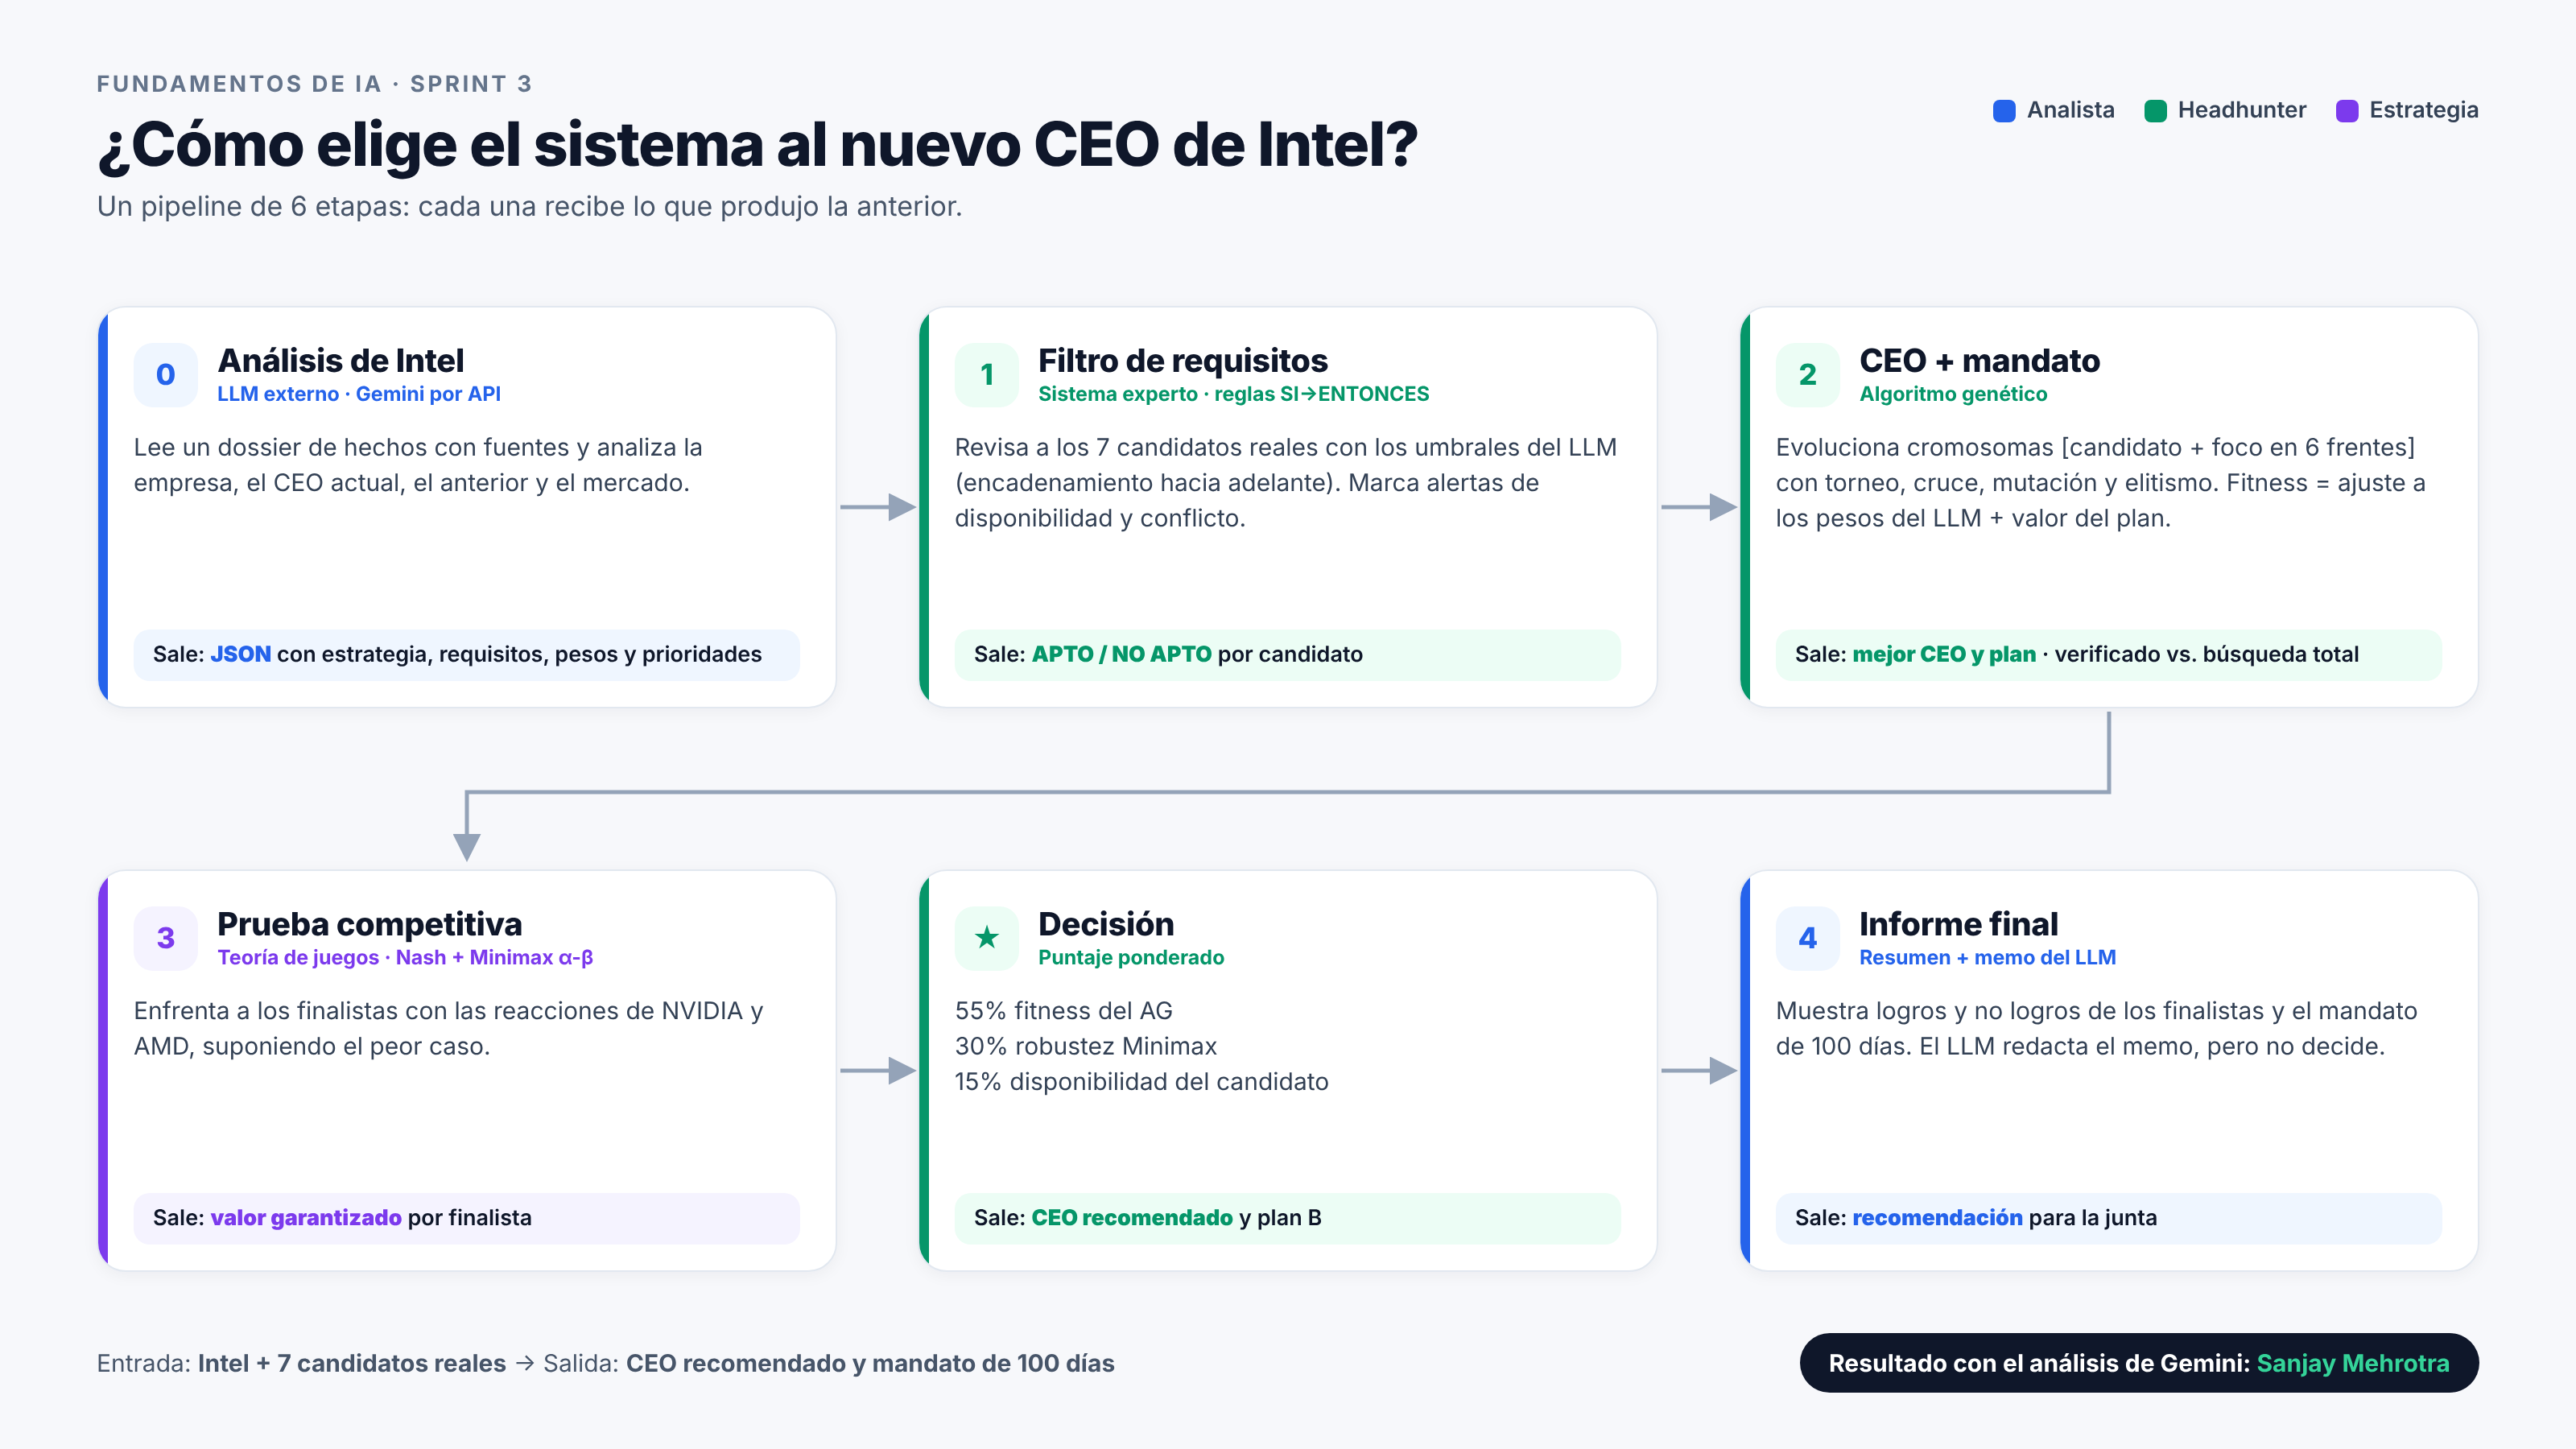

In [ ]:
# ==============================================================================
# 0. LIBRERÍAS Y CONFIGURACIÓN GENERAL
# ==============================================================================
import os, json, math, random, textwrap, itertools
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEMILLA = 42
random.seed(SEMILLA)
rng = np.random.default_rng(SEMILLA)
pd.set_option("display.max_colwidth", 120)

EMPRESA = "Intel Corporation"
FECHA_ANALISIS = "2026-10-15"

# ---- Configuración del LLM externo ----
PROVEEDOR_LLM = "gemini"          # "gemini" u "openai"
MODELOS_GEMINI = ["gemini-2.5-flash", "gemini-flash-latest", "gemini-2.5-flash-lite",
                  "gemini-flash-lite-latest", "gemini-2.0-flash"]  # se prueban en orden
MODELO_OPENAI = "gpt-4o-mini"


def obtener_api_key(nombre):
    """Busca la API key en los Secrets de Colab y, si no está, en las variables de entorno."""
    try:
        from google.colab import userdata
        valor = userdata.get(nombre)
        if valor:
            return valor
    except Exception:
        pass
    return os.environ.get(nombre)

## PASO 0 — Análisis de la empresa con un LLM externo

**Rol: analista del contexto de la industria tecnológica.**

Para que el LLM no "invente" el contexto, le entregamos un **dossier de hechos verificados con fuente** (corte: 15 de octubre de 2026). Le pedimos que, a partir de él:

1. diagnostique a Intel (fortalezas, debilidades, oportunidades, amenazas);
2. analice al **CEO actual** y el **legado del CEO anterior** (las decisiones que dejaron a Intel atrás frente a NVIDIA);
3. identifique la **problemática central** y las **tendencias del mercado**;
4. diseñe una **estrategia de reclutamiento** y el perfil del nuevo CEO;
5. traduzca ese perfil a **números**: requisitos rígidos (Paso 1), pesos de los criterios y prioridades de los frentes estratégicos (Paso 2).

El LLM debe responder **solo en JSON** con un esquema fijo. Así su salida se puede validar y conectar con el código.

In [ ]:
# ==============================================================================
# 0.1 DOSSIER DE CONTEXTO (hechos con fuente) QUE SE ENVÍA AL LLM
# ==============================================================================
DOSSIER_INTEL = {
    "fecha_corte": FECHA_ANALISIS,
    "ceo_actual": {
        "nombre": "Lip-Bu Tan",
        "desde": "marzo de 2025",
        "trayectoria": "CEO de Cadence Design Systems (2009–2021); fundador de Walden International (capital de riesgo); "
                       "miembro de la junta de Intel hasta agosto de 2024, cuando renunció por desacuerdos con la estrategia.",
        "decisiones": [
            "Reducción fuerte de plantilla y recorte de gastos operativos durante 2025.",
            "Cancelación o retraso de fábricas (Alemania y Polonia canceladas; Ohio desacelerada).",
            "Venta del 51% de Altera a Silver Lake.",
            "Entrada del Gobierno de EE. UU. como mayor accionista (~10%, agosto de 2025), inversión de NVIDIA por US$5.000 M "
            "(sept. 2025, a US$23,28 por acción) y de SoftBank por US$2.000 M.",
            "Lanzamiento de Panther Lake en el nodo 18A; kit de diseño (PDK) 0.9 del nodo 14A para clientes externos en octubre de 2026.",
        ],
        "resultados_recientes": "Q2 2026: ingresos US$16.100 M (+25% interanual, el mayor crecimiento desde 2011); Data Center e IA "
                                "US$6.300 M (+59%); Foundry US$5.800 M (+31%); margen bruto GAAP 40,4% (vs. 27,5%). Pérdida neta GAAP "
                                "de US$11.000 M por un ajuste contable ligado al acuerdo CHIPS. La demanda de CPU para servidores supera "
                                "la capacidad.",
        "controversias": "En agosto de 2025 el presidente de EE. UU. pidió públicamente su renuncia por sus inversiones ligadas a China; "
                         "luego se reunieron y el Gobierno terminó tomando una participación en Intel.",
    },
    "ceo_anterior": {
        "nombre": "Pat Gelsinger",
        "periodo": "febrero de 2021 – diciembre de 2024 (salida forzada por la junta)",
        "decisiones": [
            "Estrategia IDM 2.0: ser fabricante propio y foundry para terceros; plan de '5 nodos en 4 años'.",
            "Inversiones masivas en fábricas (Arizona, Ohio, Alemania) sin clientes externos de foundry comprometidos.",
            "Apuesta tardía y débil por aceleradores de IA (Gaudi no alcanzó la meta de US$500 M en 2024).",
            "2024: pérdida neta de ~US$18.700 M, suspensión del dividendo y recorte de ~15% de la plantilla.",
        ],
        "antecesores": "Brian Krzanich (2013–2018) y Bob Swan (2019–2021): retrasos de 10 nm y 7 nm, pérdida del liderazgo de "
                       "manufactura frente a TSMC y de la oportunidad de IA en GPU frente a NVIDIA.",
    },
    "mercado": {
        "nvidia": "Q2 del año fiscal 2027 (trimestre cerrado el 26-jul-2026): ingresos de US$96.200 M (+106%), Data Center "
                  "US$89.000 M, margen bruto del 75%. Es el líder absoluto en aceleradores de IA.",
        "amd": "Q1 2026 (Mercury Research): AMD tiene el 33,2% de las unidades y el 46,2% de los ingresos de CPU x86 para servidores. "
               "Intel conserva cerca del 70% del mercado de PC.",
        "tsmc": "Líder de la manufactura avanzada (N2 en producción desde finales de 2025); inversión anunciada de US$165.000 M en Arizona.",
        "foundry_intel": "Ningún cliente externo ha firmado aún un compromiso formal de volumen en 14A. Se reporta que Apple evalúa 14A "
                         "(acuerdo preliminar) y que Intel se unió al proyecto Terafab (Tesla/SpaceX/xAI). Producción de riesgo de 14A "
                         "en 2028 y de volumen en 2029.",
        "tendencias": [
            "Demanda explosiva de cómputo para IA (aceleradores, CPU para servidores de IA, memoria HBM, empaquetado avanzado).",
            "Chips a medida (ASIC/XPU) de los hiperescaladores: Google, Amazon, Microsoft, Meta, OpenAI y Anthropic.",
            "Soberanía tecnológica y relocalización de la manufactura en EE. UU. y Europa (CHIPS Act).",
            "Avance de Arm en PC y centros de datos; competencia en 'AI PC'.",
            "Escasez de capacidad en nodos avanzados y empaquetado (CoWoS/Foveros).",
        ],
    },
    "fuentes": [
        "Intel Q2 2026 earnings — Yahoo Finance, 23-jul-2026",
        "NVIDIA Form 8-K Q2 FY2027 — SEC, 26-ago-2026",
        "Mercury Research vía Tom's Hardware, 14-may-2026",
        "AI Weekly, 'Intel livre son PDK 14A en octobre', 27-jun-2026",
        "CNN/CNBC: inversión de NVIDIA en Intel, 18-sep-2025",
        "Wikipedia: Pat Gelsinger",
    ],
}

In [ ]:
# ==============================================================================
# 0.2 CLIENTE DEL LLM EXTERNO (llamada por API REST)
# ==============================================================================
INSTRUCCION_SISTEMA = (
    "Eres un analista senior del contexto de la industria tecnológica y de semiconductores y un experto en "
    "gobierno corporativo y búsqueda de ejecutivos (executive search). Respondes en español, con rigor, "
    "basándote en los hechos que se te entregan. Respondes ÚNICAMENTE con un objeto JSON válido."
)

ESQUEMA_RESPUESTA = """{
  "empresa": "string",
  "diagnostico_empresa": {
    "resumen": "string (5-7 líneas)",
    "fortalezas": ["string"], "debilidades": ["string"],
    "oportunidades": ["string"], "amenazas": ["string"]
  },
  "analisis_ceo_actual": {
    "nombre": "string", "aciertos": ["string"], "limitaciones": ["string"],
    "por_que_se_requiere_un_cambio": "string"
  },
  "legado_ceo_anterior": {
    "nombre": "string", "decisiones_que_dejaron_atras_a_intel": ["string"]
  },
  "problematica_central": "string",
  "tipo_crisis": "TECNOLOGICA | FINANCIERA | GOBERNANZA | MIXTA",
  "tendencias_mercado": ["string"],
  "estrategia_reclutamiento": {
    "nombre": "string",
    "pilares": ["string"],
    "perfil_ideal": "string",
    "preguntas_clave_entrevista": ["string"],
    "senales_de_alerta": ["string"]
  },
  "requisitos_rigidos": {
    "exp_min_ceo_anos": "entero entre 3 y 15 (años mínimos como CEO)",
    "min_tecnologia": "número 0-10 (dominio mínimo en semiconductores)",
    "min_gobernanza": "número 0-10 (integridad y gobierno corporativo mínimos)",
    "min_transformacion": "número 0-10 (historial mínimo liderando transformaciones)"
  },
  "pesos_criterios": {
    "tecnologia": "peso", "manufactura": "peso", "ia": "peso", "finanzas": "peso",
    "transformacion": "peso", "liderazgo": "peso", "ecosistema": "peso", "gobernanza": "peso"
  },
  "prioridades_frentes": {
    "foundry": "peso", "aceleradores_ia": "peso", "cpu_data_center": "peso",
    "pc_ia": "peso", "eficiencia_costos": "peso", "alianzas": "peso"
  },
  "justificacion_cuantitativa": "string: por qué esos requisitos, pesos y prioridades"
}"""

def construir_prompt(dossier):
    return f"""
Contexto: un software académico de reclutamiento busca al mejor CEO para {EMPRESA}. La empresa se quedó atrás
por decisiones de sus CEO anteriores y fue superada por NVIDIA. Se necesita un CEO que la desestanque y la
impulse en la industria tecnológica mundial. Fecha del análisis: {FECHA_ANALISIS}.

DOSSIER DE HECHOS VERIFICADOS (úsalo como base; no inventes cifras que no estén aquí):
{json.dumps(dossier, ensure_ascii=False, indent=2)}

TAREA:
1. Analiza la empresa, a su CEO actual y el legado del CEO anterior.
2. Explica la problemática central y por qué se requiere un nuevo tipo de liderazgo.
3. Diseña una estrategia de reclutamiento y el perfil del nuevo CEO.
4. Traduce el perfil a números para el sistema:
   - requisitos_rigidos: umbrales mínimos (escala 0-10, años en enteros). Sé exigente pero realista: un umbral
     demasiado alto deja sin candidatos.
   - pesos_criterios: 8 pesos no negativos que sumen 1.
   - prioridades_frentes: 6 pesos no negativos que sumen 1 (dónde debe enfocar el nuevo CEO sus primeros 100 días).

Responde SOLO con un JSON que siga exactamente este esquema:
{ESQUEMA_RESPUESTA}
"""


def _llamar_gemini(prompt, api_key, reintentos=3):
    """Prueba cada modelo de la lista; si está saturado (503/429/500) espera y reintenta."""
    import time
    errores = []
    for modelo in MODELOS_GEMINI:
        url = f"https://generativelanguage.googleapis.com/v1beta/models/{modelo}:generateContent"
        cuerpo = {
            "systemInstruction": {"parts": [{"text": INSTRUCCION_SISTEMA}]},
            "contents": [{"role": "user", "parts": [{"text": prompt}]}],
            "generationConfig": {"temperature": 0.2, "responseMimeType": "application/json"},
        }
        for intento in range(1, reintentos + 1):
            try:
                r = requests.post(url, headers={"x-goog-api-key": api_key, "Content-Type": "application/json"},
                                  json=cuerpo, timeout=180)
            except requests.exceptions.RequestException as ex:
                errores.append(f"{modelo}: {ex}")
                time.sleep(5 * intento)
                continue
            if r.status_code == 200:
                datos = r.json()
                texto = "".join(p.get("text", "") for p in datos["candidates"][0]["content"]["parts"])
                return texto, modelo
            errores.append(f"{modelo}: HTTP {r.status_code}")
            if r.status_code in (401, 403):            # clave inválida o sin permiso: no sirve reintentar
                raise RuntimeError(f"La API key fue rechazada (HTTP {r.status_code}). Revisa GEMINI_API_KEY. {r.text[:200]}")
            if r.status_code in (429, 500, 503):        # saturado o límite por minuto → esperar y reintentar
                espera = 10 * intento
                print(f"⏳ {modelo} ocupado (HTTP {r.status_code}). Reintento {intento}/{reintentos} en {espera} s...")
                time.sleep(espera)
                continue
            break                                       # 404/400 → modelo no disponible: pasar al siguiente
        print(f"↪️ Probando con el siguiente modelo...")
    raise RuntimeError("Falló la llamada a Gemini con todos los modelos. Espera unos minutos y vuelve a ejecutar.\n"
                       + "\n".join(errores))


def _llamar_openai(prompt, api_key):
    r = requests.post(
        "https://api.openai.com/v1/chat/completions",
        headers={"Authorization": f"Bearer {api_key}", "Content-Type": "application/json"},
        json={"model": MODELO_OPENAI, "temperature": 0.2,
              "response_format": {"type": "json_object"},
              "messages": [{"role": "system", "content": INSTRUCCION_SISTEMA},
                           {"role": "user", "content": prompt}]},
        timeout=180)
    if r.status_code != 200:
        raise RuntimeError(f"Falló la llamada a OpenAI: HTTP {r.status_code} — {r.text[:300]}")
    return r.json()["choices"][0]["message"]["content"], MODELO_OPENAI


def consultar_llm(prompt, proveedor=PROVEEDOR_LLM):
    """Envía el prompt al LLM externo y devuelve (texto_respuesta, modelo_usado)."""
    nombre_key = "GEMINI_API_KEY" if proveedor == "gemini" else "OPENAI_API_KEY"
    api_key = obtener_api_key(nombre_key)
    if not api_key:
        raise RuntimeError(f"No se encontró {nombre_key}. Agrégala en los Secrets de Colab (ícono 🔑) "
                           f"y activa 'Notebook access'.")
    return _llamar_gemini(prompt, api_key) if proveedor == "gemini" else _llamar_openai(prompt, api_key)


def extraer_json(texto):
    """Convierte la respuesta en dict aunque el LLM la envuelva en ```json ... ```."""
    texto = texto.strip()
    if texto.startswith("```"):
        texto = texto.split("```")[1]
        texto = texto[4:] if texto.lower().startswith("json") else texto
    inicio, fin = texto.find("{"), texto.rfind("}")
    return json.loads(texto[inicio:fin + 1])

In [ ]:
# ==============================================================================
# 0.3 EJECUCIÓN DEL PASO 0: CONSULTA AL LLM
# ==============================================================================
prompt_paso0 = construir_prompt(DOSSIER_INTEL)
respuesta_texto, MODELO_USADO = consultar_llm(prompt_paso0)
analisis_llm = extraer_json(respuesta_texto)

with open("paso0_respuesta_llm.json", "w", encoding="utf-8") as f:   # evidencia de la consulta
    json.dump(analisis_llm, f, ensure_ascii=False, indent=2)

print(f"✅ Respuesta recibida de {PROVEEDOR_LLM} ({MODELO_USADO}) y guardada en paso0_respuesta_llm.json")

↪️ Probando con el siguiente modelo...
✅ Respuesta recibida de gemini (gemini-flash-latest) y guardada en paso0_respuesta_llm.json


In [ ]:
# ==============================================================================
# 0.4 VALIDACIÓN DEL JSON → CONFIGURACIÓN DEL PIPELINE
# ==============================================================================
CRITERIOS = ["tecnologia", "manufactura", "ia", "finanzas", "transformacion", "liderazgo", "ecosistema", "gobernanza"]
FRENTES = ["foundry", "aceleradores_ia", "cpu_data_center", "pc_ia", "eficiencia_costos", "alianzas"]


def _a_numero(valor, defecto):
    try:
        return float(valor)
    except (TypeError, ValueError):
        return defecto


def normalizar_pesos(diccionario, claves):
    """Lleva los pesos a [0, ∞), completa los faltantes y hace que sumen 1."""
    v = np.array([max(0.0, _a_numero((diccionario or {}).get(k), 0.0)) for k in claves])
    if v.sum() == 0:
        v = np.ones(len(claves))
    return dict(zip(claves, v / v.sum()))


def validar_configuracion(a):
    """El LLM es una fuente externa: se valida y se acota todo lo que llega antes de usarlo."""
    req = a.get("requisitos_rigidos", {}) or {}
    return {
        "tipo_crisis": a.get("tipo_crisis", "MIXTA"),
        "requisitos": {
            "exp_min_ceo_anos": int(np.clip(_a_numero(req.get("exp_min_ceo_anos"), 5), 3, 15)),
            "min_tecnologia": float(np.clip(_a_numero(req.get("min_tecnologia"), 7), 0, 9.5)),
            "min_gobernanza": float(np.clip(_a_numero(req.get("min_gobernanza"), 7), 0, 9.5)),
            "min_transformacion": float(np.clip(_a_numero(req.get("min_transformacion"), 6), 0, 9.5)),
        },
        "pesos": normalizar_pesos(a.get("pesos_criterios"), CRITERIOS),
        "prioridades": normalizar_pesos(a.get("prioridades_frentes"), FRENTES),
    }


CONFIG = validar_configuracion(analisis_llm)

print("Tipo de crisis:", CONFIG["tipo_crisis"])
print("Requisitos rígidos:", CONFIG["requisitos"])
display(pd.DataFrame({"peso criterio": CONFIG["pesos"]}).T.round(3))
display(pd.DataFrame({"prioridad frente": CONFIG["prioridades"]}).T.round(3))

Tipo de crisis: MIXTA
Requisitos rígidos: {'exp_min_ceo_anos': 5, 'min_tecnologia': 8.5, 'min_gobernanza': 8.5, 'min_transformacion': 8.0}


,tecnologia,manufactura,ia,finanzas,transformacion,liderazgo,ecosistema,gobernanza
peso criterio,0.15,0.15,0.15,0.08,0.15,0.12,0.1,0.1


,foundry,aceleradores_ia,cpu_data_center,pc_ia,eficiencia_costos,alianzas
prioridad frente,0.25,0.2,0.15,0.1,0.1,0.2


In [ ]:
# ==============================================================================
# 0.5 INFORME DEL ANALISTA (salida del LLM, legible)
# ==============================================================================
def lista_md(items):
    return "\n".join(f"- {x}" for x in (items or []))

d = analisis_llm.get("diagnostico_empresa", {})
c = analisis_llm.get("analisis_ceo_actual", {})
l = analisis_llm.get("legado_ceo_anterior", {})
e = analisis_llm.get("estrategia_reclutamiento", {})

display(Markdown(f"""
## Informe del Paso 0 — {analisis_llm.get('empresa', EMPRESA)}
*Generado por {PROVEEDOR_LLM} ({MODELO_USADO}) a partir del dossier con corte al {FECHA_ANALISIS}.*

### Diagnóstico
{d.get('resumen', '')}

**Fortalezas**
{lista_md(d.get('fortalezas'))}

**Debilidades**
{lista_md(d.get('debilidades'))}

**Oportunidades**
{lista_md(d.get('oportunidades'))}

**Amenazas**
{lista_md(d.get('amenazas'))}

### CEO actual: {c.get('nombre', '')}
**Aciertos**
{lista_md(c.get('aciertos'))}

**Limitaciones**
{lista_md(c.get('limitaciones'))}

**¿Por qué se requiere un cambio?** {c.get('por_que_se_requiere_un_cambio', '')}

### Legado del CEO anterior: {l.get('nombre', '')}
{lista_md(l.get('decisiones_que_dejaron_atras_a_intel'))}

### Problemática central
{analisis_llm.get('problematica_central', '')}

### Tendencias del mercado
{lista_md(analisis_llm.get('tendencias_mercado'))}

---
## Nueva estrategia de reclutamiento: {e.get('nombre', '')}
**Pilares**
{lista_md(e.get('pilares'))}

**Perfil ideal del nuevo CEO:** {e.get('perfil_ideal', '')}

**Preguntas clave para la entrevista**
{lista_md(e.get('preguntas_clave_entrevista'))}

**Señales de alerta (descartar si aparecen)**
{lista_md(e.get('senales_de_alerta'))}

**Justificación de los números:** {analisis_llm.get('justificacion_cuantitativa', '')}
"""))


## Informe del Paso 0 — Intel Corporation
*Generado por gemini (gemini-flash-latest) a partir del dossier con corte al 2026-10-15.*

### Diagnóstico
A octubre de 2026, Intel experimenta una estabilización operativa táctica impulsada por la reestructuración de Lip-Bu Tan, logrando un crecimiento interanual de ingresos del 25% en el Q2 2026 y márgenes brutos recuperados al 40,4%. No obstante, la compañía arrastra una pérdida neta contable de US$11.000 M vinculada al acuerdo CHIPS y enfrenta una crisis estratégica estructural frente a NVIDIA y TSMC. Aunque Panther Lake en 18A está operativo y el PDK 0.9 de 14A ya está en manos de clientes, Intel Foundry carece de contratos vinculantes de volumen a gran escala. Además, AMD ha capturado el 46,2% de los ingresos de CPU para servidores y el negocio de aceleradores de IA sigue rezagado. La presencia del Gobierno de EE. UU. como accionista del 10% confiere estabilidad geopolítica pero restringe la agilidad corporativa.

**Fortalezas**
- Liderazgo consolidado en el mercado de PC x86 con cerca del 70% de cuota de mercado.
- Demanda de CPU para servidores superando la capacidad instalada actual (crecimiento de Data Center e IA al +59% en Q2 2026).
- Avance en la hoja de ruta de procesos: lanzamiento de Panther Lake en 18A y entrega de PDK 0.9 del nodo 14A.
- Respaldo financiero y soberano estratégico del Gobierno de EE. UU. (~10% accionarial) y alianzas de capital con NVIDIA (US$5.000 M) y SoftBank (US$2.000 M).
- Infraestructura avanzada de empaquetado (Foveros) y participación incipiente en consorcios estratégicos como el proyecto Terafab.

**Debilidades**
- Ausencia de compromisos formales vinculantes de volumen para el nodo 14A por parte de clientes externos de primer nivel.
- Pérdida crítica de cuota de ingresos en CPU de servidores frente a AMD (46,2% en manos de AMD en Q1 2026).
- Retraso severo en aceleradores de IA frente a NVIDIA, tras el fracaso comercial de la línea Gaudi.
- Estructura financiera impactada por amortizaciones y ajustes contables masivos ligados al CHIPS Act (pérdida neta de US$11.000 M en Q2 2026).
- Capacidad fabril comprometida o demorada tras la cancelación de expansiones en Alemania y Polonia y la desaceleración en Ohio.

**Oportunidades**
- Consolidación como la principal 'Foundry' de confianza en suelo estadounidense para hiperescaladores y diseñadores 'fabless' (ej. acuerdo preliminar con Apple).
- Fabricación de silicio personalizado (ASIC/XPU) y empaquetado avanzado para hiperescaladores en busca de alternativas a la saturación de TSMC.
- Monetización del auge de 'AI PC' apalancando la arquitectura Panther Lake y la posición dominante en ordenadores personales.
- Captura de subvenciones y contratos de defensa y seguridad nacional bajo el marco de soberanía tecnológica en EE. UU.

**Amenazas**
- Monopolio de facto de NVIDIA en el ecosistema de IA empresarial y de centros de datos (US$89.000 M en DC en un solo trimestre).
- Dominio implacable de TSMC en nodos sub-2nm (N2 en producción y masiva expansión en Arizona por US$165.000 M).
- Migración de la industria de servidores y PC hacia arquitecturas Arm promovida por hiperescaladores y competidores fabless.
- Interferencia política y restricciones regulatorias derivadas de la participación del 10% del gobierno estadounidense.

### CEO actual: Lip-Bu Tan
**Aciertos**
- Disciplina de capital inmediata: detención de sangría de efectivo cancelando fábricas sobredimensionadas en Europa y desacelerando Ohio.
- Monetización de activos no estratégicos, como la venta del 51% de Altera a Silver Lake.
- Inyecciones de capital institucional y estratégico clave (NVIDIA US$5.000 M, SoftBank US$2.000 M y Gobierno de EE. UU.).
- Ejecución técnica enfocada: entrega puntual de Panther Lake (18A) y distribución del PDK 0.9 para el nodo 14A.
- Recuperación del margen bruto al 40,4% y repunte trimestral de ingresos a US$16.100 M (+25% interanual).

**Limitaciones**
- Vulnerabilidad política y fricción regulatoria evidenciada por la solicitud pública de renuncia por parte del presidente de EE. UU. debido a sus nexos con China.
- Enfoque marcadamente defensivo y de contracción ('cost-cutter'), sin una visión agresiva de producto para competir frontalmente en aceleradores de IA.
- Falta de acuerdos comerciales firmes de gran escala para la división Foundry más allá de evaluaciones preliminares.
- Perfil de transición y gestión de crisis, no de arquitecto de ecosistema a largo plazo para la era de la IA generativa.

**¿Por qué se requiere un cambio?** Lip-Bu Tan estabilizó financieramente la empresa y frenó la quema descontrolada de caja, pero su perfil como inversor de capital de riesgo y sus pasivos geopolíticos limitan su capacidad para liderar a Intel en su próxima fase ofensiva. Intel necesita un líder que combine legitimidad política intachable ante Washington con la capacidad técnica de cerrar contratos comerciales masivos en Foundry y reposicionar radicalmente a la compañía en silicio acelerador de IA y computación heterogénea.

### Legado del CEO anterior: Pat Gelsinger
- Lanzamiento de la estrategia IDM 2.0 con inversiones masivas en infraestructura ('shell-first') sin compromisos de clientes comerciales externos garantizados.
- Subestimación de la revolución de las GPU y aceleradores para IA generativa; incapacidad de escalar comercialmente la línea Gaudi (incumpliendo el objetivo de US$500 M).
- Sobreexpansión geográfica costosa en Europa y EE. UU. que destruyó la liquidez, provocando una pérdida neta de US$18.700 M en 2024 y la suspensión del histórico dividendo.
- Incapacidad de frenar la pérdida sistemática de cuota de mercado en procesadores de centros de datos ante la arquitectura EPYC de AMD.
- Planes de ejecución excesivamente agresivos ('5 nodos en 4 años') que desalinearon el gasto de capital con la demanda real del mercado.

### Problemática central
Intel opera en un desfase estratégico multidimensional: resolvió temporalmente su solvencia y ejecución técnica básica en manufactura (18A/14A), pero carece de un modelo comercial validado por clientes externos en Foundry, sigue desprovista de una propuesta competitiva en aceleradores de IA frente a NVIDIA, y cede ingresos críticos en centros de datos frente a AMD, todo mientras está sujeta al escrutinio geopolítico del gobierno de EE. UU. como su principal accionista.

### Tendencias del mercado
- Concentración exponencial del gasto de capital tecnológico en clústeres de aceleración de IA y empaquetado avanzado (CoWoS/Foveros).
- Transición de los hiperescaladores (Microsoft, Google, Meta, AWS) hacia silicio personalizado (ASIC) y aceleradores propietarios, reduciendo la dependencia de CPU generalistas.
- Bipolarización geopolítica y demanda estricta de cadenas de suministro de semiconductores 'onshore' y 'nearshore' bajo mandatos de soberanía nacional.
- Penetración acelerada de núcleos basados en arquitectura Arm en infraestructuras de nube y plataformas de cómputo cliente (AI PC).
- Ruptura de la paridad en centros de datos: AMD capturando el valor de margen alto mientras NVIDIA domina el cómputo acelerado.

---
## Nueva estrategia de reclutamiento: Proyecto Prometheus: Liderazgo de Cómputo Soberano y Escala de Silicio
**Pilares**
- Validación comercial inmediata de Foundry: Convertir compromisos exploratorios (como Apple y Terafab) en contratos 'take-or-pay' de gran escala para el nodo 14A.
- Pivote en la arquitectura de IA: Reorganizar la cartera de productos hacia silicio específico para inferencia y co-diseño de ASICs con hiperescaladores en lugar de competir de frente en el stack de entrenamiento de NVIDIA.
- Alineación geopolítica y diplomacia corporativa: Capacidad fluida para operar bajo supervisión de Washington protegiendo los intereses fiduciarios de los accionistas privados y socios como NVIDIA y SoftBank.
- Cultura de entrega implacable: Consolidar la separación operativa entre Intel Products e Intel Foundry para eliminar conflictos de interés percibidos por clientes externos.

**Perfil ideal del nuevo CEO:** Ejecutivo sénior de la industria de semiconductores con doble competencia demostrada: liderazgo técnico en diseño avanzado/fabricación y trayectoria comercial indiscutible cerrando acuerdos multimillonarios con empresas 'hyperscale'. Debe poseer intachables credenciales de seguridad nacional en EE. UU., reputación intachable en Wall Street, y el rigor operativo necesario para gestionar una organización de más de 100.000 empleados en transformación estructural sin fricciones de gobernanza.

**Preguntas clave para la entrevista**
- ¿Cómo estructuraría las garantías operativas y de propiedad intelectual para que competidores directos como Apple, Qualcomm o NVIDIA contraten capacidad en Intel 14A sin temor a filtraciones hacia Intel Products?
- Dada la participación accionarial del 10% del gobierno de EE. UU., ¿cómo gestionará las presiones proteccionistas para levantar fábricas geopolíticamente estratégicas pero financieramente subóptimas?
- Con NVIDIA dominando el 75%+ de margen y AMD con casi la mitad de los ingresos de CPU para servidores, ¿cuál es su plan concreto a 24 meses para que la división de Data Center de Intel vuelva al crecimiento rentable?
- ¿Qué decisiones tomaría con respecto a la línea de aceleradores de IA de Intel: continuar desarrollando silicio propio generalista o transformar la división en un taller de co-diseño ASIC para hiperescaladores?
- ¿Cuál es su estrategia para retener el 70% de cuota en PC frente a la embestida de los procesadores basados en Arm respaldados por los grandes proveedores de sistemas operativos?

**Señales de alerta (descartar si aparecen)**
- Historial de inversiones complejas o dependencias comerciales opacas en jurisdicciones de riesgo geopolítico (ej. China continental) que activen vetos gubernamentales.
- Perfil puramente financiero o de reestructuración ('cost-cutter') sin entendimiento profundo de la física de semiconductores y el ecosistema EDA/PDK.
- Líderes dogmáticos comprometidos con el modelo IDM tradicional que se resistan a la separación operacional total de la división Foundry.
- Incapacidad para demostrar relaciones de confianza a nivel de junta directiva con los CEO de los principales clientes fabless (Apple, AMD, NVIDIA, hiperescaladores).

**Justificación de los números:** Los requisitos rígidos fijan 5 años mínimos como CEO para garantizar que el candidato haya liderado a escala pública compleja; tecnología y gobernanza se establecen en 8.5/10 debido a la naturaleza hiperespecializada del silicio sub-2nm y a la presencia del Gobierno de EE. UU. como principal accionista (~10%), lo que no admite fallos de cumplimiento o conflictos de interés. Transformación exige 8.0/10 para ejecutar la escisión práctica y cultural de Foundry. En los pesos de criterios (suma = 1.00), Tecnología (0.15), Manufactura (0.15), IA (0.15) y Transformación (0.15) concentran el 60% del peso, reflejando que la supervivencia depende de entregar el nodo 14A, diseñar silicio competitivo y transformar el modelo IDM; Gobernanza (0.10), Ecosistema (0.10) y Liderazgo (0.12) aseguran alineación política y captación de clientes externos, mientras Finanzas (0.08) pasa a segundo plano dado que la liquidez inmediata fue saneada por Tan. En las prioridades de los primeros 100 días (suma = 1.00), Foundry (0.25) es la máxima urgencia para convertir el PDK 0.9 de 14A en contratos de volumen; Aceleradores IA (0.20) y Alianzas (0.20) son críticos para reposicionar a Intel en el 'capex' de hiperescaladores y formalizar acuerdos con Apple/Terafab; CPU Data Center (0.15) debe defender los márgenes frente a AMD; y PC IA (0.10) y Eficiencia de costos (0.10) reciben menor ponderación inicial porque la base de PC ya lidera (70%) y el recorte de gastos ya fue ejecutado drásticamente durante 2025.


## Rol HEADHUNTER — Base de candidatos reales

Ahora pasamos al rol de **headhunter**. La base tiene **7 ejecutivos reales** de la industria de semiconductores. Para cada uno se resume, con fuentes públicas, **qué logró y qué no logró** en sus cargos anteriores.

**Importante (uso académico):**
- Los puntajes 0–10 son **estimaciones del equipo** a partir de esa evidencia pública. No son mediciones oficiales ni una evaluación real de esas personas.
- `disponibilidad` es la probabilidad estimada de que el ejecutivo acepte el cargo. La mayoría hoy dirige otra empresa, y eso se modela como un **riesgo** (alerta en el Paso 1 y peso en la decisión final), no como un descarte.
- Pat Gelsinger se incluye como **candidato de control**: el sistema debería detectar que su perfil no resuelve la problemática actual.

In [ ]:
# ==============================================================================
# 1. BASE DE CONOCIMIENTO — CANDIDATOS (MEMORIA DE TRABAJO)
# ==============================================================================
candidatos_db = [
    {
        "id": "C1", "nombre": "Lisa Su", "cargo_actual": "Presidenta y CEO de AMD (desde 2014)",
        "exp_ceo": 12, "tecnologia": 9.5, "manufactura": 6.5, "ia": 8.5, "finanzas": 8.5, "transformacion": 9.5,
        "liderazgo": 9.5, "ecosistema": 9.0, "gobernanza": 9.5, "disponibilidad": 0.10, "conflicto_interes": True,
        "logros": [
            "Rescató a AMD de una situación cercana a la quiebra (2014) con la arquitectura Zen y el diseño por chiplets.",
            "Llevó a AMD al 46% de los ingresos de CPU x86 para servidores (Q1 2026), casi todo ganado a Intel.",
            "Compró Xilinx (~US$49.000 M, 2022) y construyó la línea Instinct (MI300/MI400) de aceleradores de IA.",
            "Firmó acuerdos de varios gigavatios con OpenAI (2025) y Meta (2026) para la serie MI450.",
        ],
        "no_logros": [
            "La participación de AMD en aceleradores de IA sigue siendo pequeña frente a NVIDIA.",
            "Su ecosistema de software (ROCm) va detrás de CUDA.",
            "Nunca ha dirigido fábricas propias: AMD es fabless y depende de TSMC.",
        ],
    },
    {
        "id": "C2", "nombre": "C.C. Wei", "cargo_actual": "Presidente de la junta y CEO de TSMC",
        "exp_ceo": 8, "tecnologia": 8.5, "manufactura": 10.0, "ia": 7.5, "finanzas": 8.5, "transformacion": 6.5,
        "liderazgo": 8.5, "ecosistema": 9.5, "gobernanza": 9.0, "disponibilidad": 0.05, "conflicto_interes": True,
        "logros": [
            "Como CEO (2018) y presidente (2024) consolidó a TSMC como líder mundial en N5, N3 y N2.",
            "Es el fabricante de los chips de IA de NVIDIA, AMD, Apple y los hiperescaladores; amplió el empaquetado CoWoS.",
            "Lideró la expansión en Arizona, con un compromiso total de US$165.000 M.",
        ],
        "no_logros": [
            "La primera fábrica de Arizona se retrasó de 2024 a 2025 por falta de mano de obra y choques culturales.",
            "No tiene experiencia dirigiendo una empresa en crisis ni el diseño de productos propios (TSMC es foundry pura).",
        ],
    },
    {
        "id": "C3", "nombre": "Hock Tan", "cargo_actual": "Presidente y CEO de Broadcom (desde 2006)",
        "exp_ceo": 20, "tecnologia": 6.5, "manufactura": 5.0, "ia": 9.0, "finanzas": 10.0, "transformacion": 9.0,
        "liderazgo": 6.5, "ecosistema": 8.5, "gobernanza": 7.0, "disponibilidad": 0.10, "conflicto_interes": True,
        "logros": [
            "Convirtió a Avago en Broadcom con adquisiciones: Broadcom (2016), CA (2018), Symantec Enterprise (2019) y VMware (US$69.000 M, 2023).",
            "Construyó el negocio de chips de IA a medida (XPU) para Google, OpenAI y Anthropic. Q3 FY2026: ingresos de US$29.600 M (+86%).",
            "Es reconocido por su disciplina de costos y márgenes muy altos.",
        ],
        "no_logros": [
            "Su oferta hostil por Qualcomm (2018) fue bloqueada por el Gobierno de EE. UU.",
            "Los cambios de licenciamiento de VMware provocaron rechazo de clientes, demandas y quejas regulatorias en Europa.",
            "Su estilo de recortes agresivos choca con una cultura de I+D como la de Intel.",
        ],
    },
    {
        "id": "C4", "nombre": "Sanjay Mehrotra", "cargo_actual": "Presidente de la junta y CEO de Micron (desde 2017)",
        "exp_ceo": 14, "tecnologia": 9.0, "manufactura": 9.0, "ia": 8.0, "finanzas": 8.0, "transformacion": 8.0,
        "liderazgo": 8.0, "ecosistema": 8.0, "gobernanza": 9.0, "disponibilidad": 0.15, "conflicto_interes": False,
        "logros": [
            "Cofundó SanDisk (1988) y, como CEO, la vendió a Western Digital por ~US$19.000 M (2016).",
            "Llevó a Micron al liderazgo en memoria HBM para IA. FY2026: ingresos récord de US$133.200 M (+256%).",
            "Dirige fábricas propias en EE. UU. y Asia; obtuvo ~US$6.100 M del CHIPS Act.",
        ],
        "no_logros": [
            "Micron llegó tarde a HBM3 frente a SK hynix.",
            "Registró una pérdida de ~US$5.800 M en el ciclo bajo de FY2023.",
            "China prohibió el uso de chips de Micron en infraestructura crítica (2023).",
        ],
    },
    {
        "id": "C5", "nombre": "Cristiano Amon", "cargo_actual": "Presidente y CEO de Qualcomm (desde 2021)",
        "exp_ceo": 5, "tecnologia": 8.5, "manufactura": 5.0, "ia": 7.0, "finanzas": 7.0, "transformacion": 7.5,
        "liderazgo": 8.0, "ecosistema": 8.5, "gobernanza": 8.5, "disponibilidad": 0.25, "conflicto_interes": True,
        "logros": [
            "Diversificó Qualcomm hacia automoción: +61% interanual en Q3 FY2026 (US$1.590 M).",
            "Entró al mercado de PC con Snapdragon X (Arm), en competencia directa con Intel.",
            "Ganó el juicio contra Arm por licencias (jurado, diciembre de 2024).",
        ],
        "no_logros": [
            "Perdió el negocio de módems de Apple; el segmento de celulares cayó 20% interanual en Q3 FY2026.",
            "Su entrada a centros de datos aún no genera ingresos relevantes.",
            "La participación de Snapdragon en PC sigue siendo pequeña.",
        ],
    },
    {
        "id": "C6", "nombre": "Rene Haas", "cargo_actual": "CEO de Arm (desde 2022) y líder de SoftBank Group International",
        "exp_ceo": 4, "tecnologia": 8.0, "manufactura": 4.0, "ia": 8.0, "finanzas": 8.0, "transformacion": 7.5,
        "liderazgo": 7.5, "ecosistema": 8.0, "gobernanza": 7.5, "disponibilidad": 0.20, "conflicto_interes": True,
        "logros": [
            "Llevó a Arm a la salida a bolsa más grande de 2023 (Nasdaq).",
            "Aumentó las regalías con Armv9 e impulsó la adopción de Arm en centros de datos.",
            "Trabajó 7 años en NVIDIA; en 2026 SoftBank amplió su rol para coordinar sus empresas de chips e IA.",
        ],
        "no_logros": [
            "Perdió el juicio contra Qualcomm (diciembre de 2024).",
            "Su giro hacia chips propios genera conflicto con los clientes de Arm.",
            "No tiene experiencia en manufactura ni en dirigir una empresa de más de 100.000 empleados.",
        ],
    },
    {
        "id": "C7", "nombre": "Pat Gelsinger", "cargo_actual": "Socio general de Playground Global; presidente ejecutivo de Gloo",
        "exp_ceo": 13, "tecnologia": 9.5, "manufactura": 7.0, "ia": 4.0, "finanzas": 3.5, "transformacion": 5.0,
        "liderazgo": 7.0, "ecosistema": 7.5, "gobernanza": 7.0, "disponibilidad": 0.90, "conflicto_interes": False,
        "logros": [
            "Fue arquitecto del 80486 y CTO de Intel (2001–2009).",
            "Como CEO de VMware (2012–2021) más que duplicó los ingresos.",
            "Impulsó el CHIPS Act y la estrategia IDM 2.0 (Intel Foundry).",
        ],
        "no_logros": [
            "Como CEO de Intel (2021–2024): pérdida de ~US$18.700 M en 2024, suspensión del dividendo y recorte de ~15% de la plantilla.",
            "Llegó tarde a la IA: Gaudi no cumplió su meta de ventas.",
            "Invirtió en fábricas sin clientes de foundry comprometidos; fue removido por la junta.",
        ],
    },
]

FUENTES_CANDIDATOS = [
    "Mercury Research vía Tom's Hardware (14-may-2026); Micron Q4 FY2026 vía Blocks & Files (01-oct-2026)",
    "Broadcom Q3 FY2026 vía DatacenterDynamics (04-sep-2026); Qualcomm Q3 FY2026 vía Futurum (03-ago-2026)",
    "Bloomberg Law: SoftBank amplía el rol de Rene Haas (21-abr-2026); Wikipedia: Pat Gelsinger, Lisa Su, C.C. Wei, Hock Tan",
]

df_candidatos = pd.DataFrame(candidatos_db).set_index("id")
display(df_candidatos[["nombre", "cargo_actual", "exp_ceo"] + CRITERIOS + ["disponibilidad", "conflicto_interes"]])

,nombre,cargo_actual,exp_ceo,tecnologia,manufactura,ia,finanzas,transformacion,liderazgo,ecosistema,gobernanza,disponibilidad,conflicto_interes
id,,,,,,,,,,,,,
C1,Lisa Su,Presidenta y CEO de AMD (desde 2014),12,9.5,6.5,8.5,8.5,9.5,9.5,9.0,9.5,0.10,True
C2,C.C. Wei,Presidente de la junta y CEO de TSMC,8,8.5,10.0,7.5,8.5,6.5,8.5,9.5,9.0,0.05,True
C3,Hock Tan,Presidente y CEO de Broadcom (desde 2006),20,6.5,5.0,9.0,10.0,9.0,6.5,8.5,7.0,0.10,True
C4,Sanjay Mehrotra,Presidente de la junta y CEO de Micron (desde 2017),14,9.0,9.0,8.0,8.0,8.0,8.0,8.0,9.0,0.15,False
C5,Cristiano Amon,Presidente y CEO de Qualcomm (desde 2021),5,8.5,5.0,7.0,7.0,7.5,8.0,8.5,8.5,0.25,True
C6,Rene Haas,CEO de Arm (desde 2022) y líder de SoftBank Group International,4,8.0,4.0,8.0,8.0,7.5,7.5,8.0,7.5,0.20,True
C7,Pat Gelsinger,Socio general de Playground Global; presidente ejecutivo de Gloo,13,9.5,7.0,4.0,3.5,5.0,7.0,7.5,7.0,0.90,False


## PASO 1 — Sistema experto: filtro de requisitos rígidos

Reutilizamos la arquitectura del **Sprint 2**: reglas **SI (antecedente) → ENTONCES (hecho)** y un motor de **encadenamiento hacia adelante** que dispara reglas hasta que no aparecen hechos nuevos.

Los **umbrales vienen del Paso 0**, es decir, de la estrategia que diseñó el LLM. Así el mismo motor sirve para otra empresa u otra crisis.

Si ningún candidato supera los umbrales, el motor aplica una **regla de relajación**: baja 0,5 puntos los umbrales y lo deja registrado. Un headhunter real hace lo mismo cuando el perfil pedido no existe en el mercado.

In [ ]:
# ==============================================================================
# 2. PASO 1 — SISTEMA EXPERTO CON ENCADENAMIENTO HACIA ADELANTE
# ==============================================================================
class Regla:
    def __init__(self, id_regla, descripcion, condicion, consecuente):
        self.id_regla, self.descripcion = id_regla, descripcion
        self.condicion, self.consecuente = condicion, consecuente


def construir_reglas(req):
    obligatorios = {"experiencia_ceo_ok", "tecnologia_ok", "gobernanza_ok", "transformacion_ok"}
    return [
        Regla("R1", f"SI años como CEO >= {req['exp_min_ceo_anos']} ENTONCES experiencia_ceo_ok",
              lambda c, h: c["exp_ceo"] >= req["exp_min_ceo_anos"], "experiencia_ceo_ok"),
        Regla("R2", f"SI tecnología >= {req['min_tecnologia']} ENTONCES tecnologia_ok",
              lambda c, h: c["tecnologia"] >= req["min_tecnologia"], "tecnologia_ok"),
        Regla("R3", f"SI gobernanza >= {req['min_gobernanza']} ENTONCES gobernanza_ok",
              lambda c, h: c["gobernanza"] >= req["min_gobernanza"], "gobernanza_ok"),
        Regla("R4", f"SI transformación >= {req['min_transformacion']} ENTONCES transformacion_ok",
              lambda c, h: c["transformacion"] >= req["min_transformacion"], "transformacion_ok"),
        Regla("R5", "SI disponibilidad < 0.30 ENTONCES riesgo_disponibilidad (alerta, no descarta)",
              lambda c, h: c["disponibilidad"] < 0.30, "riesgo_disponibilidad"),
        Regla("R6", "SI dirige hoy a un competidor/proveedor ENTONCES riesgo_conflicto (alerta, no descarta)",
              lambda c, h: c["conflicto_interes"], "riesgo_conflicto"),
        Regla("R7", "SI se cumplen R1, R2, R3 y R4 ENTONCES cumple_requisitos",
              lambda c, h: obligatorios.issubset(h), "cumple_requisitos"),
        Regla("R8", "SI cumple_requisitos ENTONCES dictamen = APTO",
              lambda c, h: "cumple_requisitos" in h, "APTO"),
    ]


def encadenamiento_adelante(candidato, reglas):
    hechos, traza, nuevo = set(), [], True
    while nuevo:
        nuevo = False
        for r in reglas:
            if r.consecuente not in hechos and r.condicion(candidato, hechos):
                hechos.add(r.consecuente)
                traza.append(r.id_regla)
                nuevo = True
    return hechos, traza


def paso1_filtrar(candidatos, req_inicial):
    req = dict(req_inicial)
    for intento in range(10):
        reglas = construir_reglas(req)
        resultados = []
        for c in candidatos:
            hechos, traza = encadenamiento_adelante(c, reglas)
            resultados.append({**c, "hechos": hechos, "traza": traza, "apto": "APTO" in hechos})
        if sum(r["apto"] for r in resultados) >= 2 or intento == 9:   # al menos 2 para poder comparar
            return resultados, req, intento
        print(f"⚠️ Regla de relajación #{intento + 1}: menos de 2 candidatos APTOS → umbrales -0.5")
        req = {k: (max(0, v - 1) if k == "exp_min_ceo_anos" else max(0, v - 0.5)) for k, v in req.items()}


evaluados_p1, REQ_FINAL, relajaciones = paso1_filtrar(candidatos_db, CONFIG["requisitos"])

print("Umbrales aplicados:", REQ_FINAL, f"(relajaciones: {relajaciones})\n")
for r in construir_reglas(REQ_FINAL):
    print(f"  {r.id_regla}: {r.descripcion}")
print()
display(pd.DataFrame([{
    "candidato": r["nombre"], "reglas disparadas": " → ".join(r["traza"]),
    "alertas": ", ".join(sorted(h for h in r["hechos"] if h.startswith("riesgo"))) or "—",
    "dictamen": "APTO" if r["apto"] else "NO APTO"} for r in evaluados_p1]))

aptos = [r for r in evaluados_p1 if r["apto"]]

Umbrales aplicados: {'exp_min_ceo_anos': 5, 'min_tecnologia': 8.5, 'min_gobernanza': 8.5, 'min_transformacion': 8.0} (relajaciones: 0)

  R1: SI años como CEO >= 5 ENTONCES experiencia_ceo_ok
  R2: SI tecnología >= 8.5 ENTONCES tecnologia_ok
  R3: SI gobernanza >= 8.5 ENTONCES gobernanza_ok
  R4: SI transformación >= 8.0 ENTONCES transformacion_ok
  R5: SI disponibilidad < 0.30 ENTONCES riesgo_disponibilidad (alerta, no descarta)
  R6: SI dirige hoy a un competidor/proveedor ENTONCES riesgo_conflicto (alerta, no descarta)
  R7: SI se cumplen R1, R2, R3 y R4 ENTONCES cumple_requisitos
  R8: SI cumple_requisitos ENTONCES dictamen = APTO



,candidato,reglas disparadas,alertas,dictamen
0,Lisa Su,R1 → R2 → R3 → R4 → R5 → R6 → R7 → R8,"riesgo_conflicto, riesgo_disponibilidad",APTO
1,C.C. Wei,R1 → R2 → R3 → R5 → R6,"riesgo_conflicto, riesgo_disponibilidad",NO APTO
2,Hock Tan,R1 → R4 → R5 → R6,"riesgo_conflicto, riesgo_disponibilidad",NO APTO
3,Sanjay Mehrotra,R1 → R2 → R3 → R4 → R5 → R7 → R8,riesgo_disponibilidad,APTO
4,Cristiano Amon,R1 → R2 → R3 → R5 → R6,"riesgo_conflicto, riesgo_disponibilidad",NO APTO
5,Rene Haas,R5 → R6,"riesgo_conflicto, riesgo_disponibilidad",NO APTO
6,Pat Gelsinger,R1 → R2,—,NO APTO


## PASO 2 — Algoritmo genético (corregido): candidato + mandato estratégico

Elegir 1 entre pocos candidatos no requiere un AG. Lo que sí es un problema combinatorio es **elegir al CEO junto con su mandato de 100 días**. Un buen CEO con el plan equivocado fracasa, como le pasó a Intel con IDM 2.0.

**Cromosoma (7 genes):** `[candidato, f_foundry, f_ia, f_cpu_dc, f_pc_ia, f_costos, f_alianzas]`
- gen 0: índice de un candidato APTO;
- genes 1–6: intensidad de foco en cada frente, de 0 (ignorar) a 3 (prioridad máxima).

**Restricción de foco:** la suma de intensidades no puede pasar de **9**. Ningún CEO puede priorizar todo a la vez.

**Función de aptitud (fitness):**

$$F = 0.45\cdot\frac{\text{ajuste}}{10} + 0.55\cdot 3\sum_f p_f\cdot \frac{\text{intensidad}_f}{3}\cdot\frac{\text{competencia}_f}{10} - \text{penalizaciones}$$

- ajuste = promedio de los 8 criterios del candidato ponderado con los **pesos del LLM** (0–10).
- $p_f$ = prioridad del frente según el LLM.
- competencia$_f$ = qué tan capaz es el candidato en ese frente (combinación de sus criterios).
- Penalizaciones: exceso de foco; **riesgo de ejecución** (intensidad 3 en un frente donde el candidato tiene competencia < 6); y **"foundry sin clientes"** (foco ≥ 2 en foundry con foco 0 en alianzas), que es la lección de IDM 2.0 del Paso 0; y **conflicto de interés** (alerta R6 del Paso 1).

**Operadores:** selección por torneo (k=3), cruce uniforme, mutación (cambio de candidato o ±1 en un frente) y elitismo.

,candidato,ajuste estratégico (0-10),alertas Paso 1
0,Lisa Su,8.77,"riesgo_conflicto, riesgo_disponibilidad"
1,Sanjay Mehrotra,8.40,riesgo_disponibilidad


🧬 Mejor individuo: Sanjay Mehrotra | plan = {'foundry': 3, 'aceleradores_ia': 3, 'cpu_data_center': 0, 'pc_ia': 0, 'eficiencia_costos': 0, 'alianzas': 3} | fitness = 1.2933
🔎 Óptimo exhaustivo (8,192 combinaciones): Sanjay Mehrotra | fitness = 1.2933
✅ El AG encontró el óptimo global


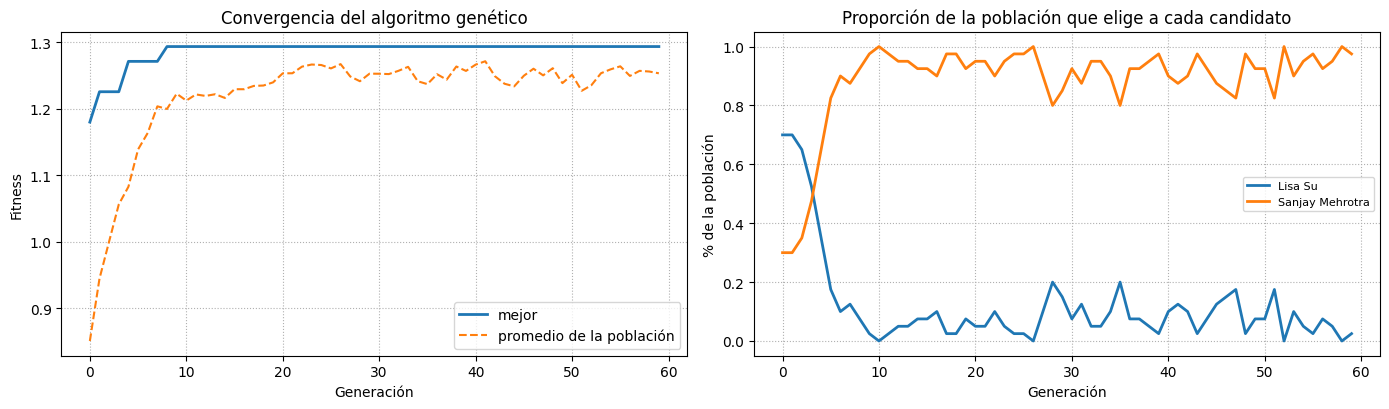

,candidato,foundry,aceleradores_ia,cpu_data_center,pc_ia,eficiencia_costos,alianzas,fitness
0,Sanjay Mehrotra,3,3,0,0,0,3,1.2933
1,Lisa Su,3,3,0,0,0,3,1.2544


In [ ]:
# ==============================================================================
# 4. PASO 2 — ALGORITMO GENÉTICO REAL
# ==============================================================================
MAPA_COMPETENCIA = {   # cómo se combinan los criterios del candidato en la competencia de cada frente
    "foundry":           {"manufactura": 0.6, "ecosistema": 0.25, "tecnologia": 0.15},
    "aceleradores_ia":   {"ia": 0.6, "tecnologia": 0.4},
    "cpu_data_center":   {"tecnologia": 0.5, "ecosistema": 0.3, "ia": 0.2},
    "pc_ia":             {"tecnologia": 0.5, "ecosistema": 0.5},
    "eficiencia_costos": {"finanzas": 0.6, "transformacion": 0.4},
    "alianzas":          {"ecosistema": 0.6, "gobernanza": 0.4},
}
MAX_FOCO, NIVELES = 9, 4   # intensidades 0..3


def ajuste_estrategico(c, pesos):
    """Promedio ponderado (0-10) de los 8 criterios con los pesos que definió el LLM en el Paso 0."""
    return sum(pesos[k] * c[k] for k in CRITERIOS)


for c in aptos:
    c["ajuste"] = ajuste_estrategico(c, CONFIG["pesos"])
display(pd.DataFrame([{"candidato": c["nombre"], "ajuste estratégico (0-10)": round(c["ajuste"], 2),
                       "alertas Paso 1": ", ".join(sorted(h for h in c["hechos"] if h.startswith("riesgo"))) or "—"}
                      for c in aptos]).sort_values("ajuste estratégico (0-10)", ascending=False))


def competencia(c, frente):
    return sum(w * c[k] for k, w in MAPA_COMPETENCIA[frente].items())


def fitness(ind, pool=None, prioridades=None):
    pool = pool if pool is not None else aptos
    prioridades = prioridades or CONFIG["prioridades"]
    c, plan = pool[ind[0]], ind[1:]
    valor_plan = sum(prioridades[f] * (plan[i] / 3) * (competencia(c, f) / 10) for i, f in enumerate(FRENTES))
    exceso = max(0, sum(plan) - MAX_FOCO)
    riesgo_ejec = sum(1 for i, f in enumerate(FRENTES) if plan[i] == 3 and competencia(c, f) < 6)
    # Lección de IDM 2.0: invertir fuerte en foundry sin un frente de alianzas/clientes es un error
    foundry_sin_clientes = 1 if (plan[0] >= 2 and plan[5] == 0) else 0
    conflicto = 1 if "riesgo_conflicto" in c["hechos"] else 0     # alerta R6 del sistema experto
    return (0.45 * c["ajuste"] / 10 + 0.55 * valor_plan * 3
            - 0.15 * exceso - 0.05 * riesgo_ejec - 0.06 * foundry_sin_clientes - 0.05 * conflicto)
    # valor_plan * 3: con foco máximo 9 se cubren ~3 frentes a intensidad 3, así ambos términos pesan parecido


def individuo_aleatorio(n):
    return [random.randrange(n)] + [random.randrange(NIVELES) for _ in FRENTES]


def torneo(poblacion, aptitudes, k=3):
    elegidos = random.sample(range(len(poblacion)), k)
    return poblacion[max(elegidos, key=lambda i: aptitudes[i])]


def cruce_uniforme(p1, p2, prob=0.9):
    if random.random() > prob:
        return p1[:], p2[:]
    h1, h2 = [], []
    for g1, g2 in zip(p1, p2):
        if random.random() < 0.5:
            h1.append(g1); h2.append(g2)
        else:
            h1.append(g2); h2.append(g1)
    return h1, h2


def mutar(ind, n, p_cand=0.10, p_gen=0.15):
    ind = ind[:]
    if random.random() < p_cand:
        ind[0] = random.randrange(n)
    for i in range(1, len(ind)):
        if random.random() < p_gen:
            ind[i] = int(np.clip(ind[i] + random.choice([-1, 1]), 0, NIVELES - 1))
    return ind


def algoritmo_genetico(pool, tam_pob=40, generaciones=60, elite=2, semilla=SEMILLA):
    random.seed(semilla)
    n = len(pool)
    poblacion = [individuo_aleatorio(n) for _ in range(tam_pob)]
    hist = {"mejor": [], "promedio": [], "proporcion": {i: [] for i in range(n)}}
    for _ in range(generaciones):
        aptitudes = [fitness(ind, pool) for ind in poblacion]
        orden = np.argsort(aptitudes)[::-1]
        hist["mejor"].append(aptitudes[orden[0]])
        hist["promedio"].append(float(np.mean(aptitudes)))
        for i in range(n):
            hist["proporcion"][i].append(sum(ind[0] == i for ind in poblacion) / tam_pob)
        nueva = [poblacion[i][:] for i in orden[:elite]]                    # elitismo
        while len(nueva) < tam_pob:
            h1, h2 = cruce_uniforme(torneo(poblacion, aptitudes), torneo(poblacion, aptitudes))
            nueva += [mutar(h1, n), mutar(h2, n)]
        poblacion = nueva[:tam_pob]
    aptitudes = [fitness(ind, pool) for ind in poblacion]
    mejor = poblacion[int(np.argmax(aptitudes))]
    return mejor, max(aptitudes), poblacion, hist


mejor_ind, mejor_fit, poblacion_final, hist_ag = algoritmo_genetico(aptos)
ceo_ag = aptos[mejor_ind[0]]
print(f"🧬 Mejor individuo: {ceo_ag['nombre']} | plan = {dict(zip(FRENTES, mejor_ind[1:]))} | fitness = {mejor_fit:.4f}")

# ---- Verificación: búsqueda exhaustiva (el espacio es pequeño, así que podemos comprobar el AG) ----
espacio = [[i] + list(p) for i in range(len(aptos)) for p in itertools.product(range(NIVELES), repeat=len(FRENTES))]
optimo = max(espacio, key=fitness)
print(f"🔎 Óptimo exhaustivo ({len(espacio):,} combinaciones): {aptos[optimo[0]]['nombre']} | fitness = {fitness(optimo):.4f}")
print("✅ El AG encontró el óptimo global" if abs(fitness(optimo) - mejor_fit) < 1e-9
      else f"ℹ️ El AG quedó a {fitness(optimo) - mejor_fit:.4f} del óptimo")

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2))
ejes[0].plot(hist_ag["mejor"], label="mejor", lw=2)
ejes[0].plot(hist_ag["promedio"], label="promedio de la población", ls="--")
ejes[0].set_title("Convergencia del algoritmo genético")
ejes[0].set_xlabel("Generación"); ejes[0].set_ylabel("Fitness"); ejes[0].legend(); ejes[0].grid(ls=":")
for i, c in enumerate(aptos):
    ejes[1].plot(hist_ag["proporcion"][i], label=c["nombre"], lw=2)
ejes[1].set_title("Proporción de la población que elige a cada candidato")
ejes[1].set_xlabel("Generación"); ejes[1].set_ylabel("% de la población"); ejes[1].legend(fontsize=8); ejes[1].grid(ls=":")
plt.tight_layout(); plt.show()

# Mejor plan posible para CADA candidato apto (sirve para comparar finalistas en el Paso 3)
mejor_por_candidato = {}
for ind in espacio:
    if ind[0] not in mejor_por_candidato or fitness(ind) > fitness(mejor_por_candidato[ind[0]]):
        mejor_por_candidato[ind[0]] = ind
ranking_ag = sorted(mejor_por_candidato.values(), key=fitness, reverse=True)
display(pd.DataFrame([{"candidato": aptos[ind[0]]["nombre"], **dict(zip(FRENTES, ind[1:])),
                       "fitness": round(fitness(ind), 4)} for ind in ranking_ag]))
finalistas = ranking_ag[:3]

## PASO 3 — Teoría de juegos: prueba de estrés competitiva de los finalistas (clase 07)

Un CEO no decide en el vacío: **NVIDIA y AMD reaccionan**. Para cada finalista modelamos dos juegos.

**a) Juego simultáneo Intel vs. NVIDIA** (no cooperativo y de suma no cero).

| Intel \ NVIDIA | **N1: Cooperar** (usar Intel Foundry / empaquetado, CPU x86 con NVLink) | **N2: Ignorar a Intel** (exclusividad con TSMC) |
|---|---|---|
| **S1: Foundry abierta** | (6 + 4·cF, 7) | (3.5 + 2·cF, 6) |
| **S2: Atacar IA de frente** | (2 + 5·cIA, 4) | (1 + 5·cIA, 8) |
| **S3: Defender CPU y costos** | (4 + 3·cC, 6) | (4 + 2·cC, 7) |

Los pagos de Intel dependen de la **competencia del CEO** (cF, cIA, cC en 0–1). Los pagos son **pedagógicos**, igual que en la clase.

**b) Juego secuencial:** Intel mueve, luego responde NVIDIA y después AMD. Se resuelve con **Minimax con poda Alfa-Beta**, suponiendo que los rivales hacen lo peor para Intel. El resultado es el **valor garantizado**: lo mínimo que Intel asegura con ese CEO.

In [ ]:
# ==============================================================================
# 5. PASO 3 — TEORÍA DE JUEGOS: NASH + MINIMAX CON PODA ALFA-BETA
# ==============================================================================
EST_INTEL = ["S1 Foundry abierta", "S2 Atacar IA", "S3 Defender CPU/costos"]
EST_NVIDIA = ["N1 Cooperar", "N2 Ignorar a Intel"]
EST_AMD = ["A1 Guerra de precios en servidores", "A2 Enfocarse en GPU de IA"]


def matriz_pagos(c):
    cF, cIA, cC = (competencia(c, "foundry") / 10, competencia(c, "aceleradores_ia") / 10,
                   competencia(c, "eficiencia_costos") / 10)
    return {
        ("S1 Foundry abierta", "N1 Cooperar"): (6 + 4 * cF, 7), ("S1 Foundry abierta", "N2 Ignorar a Intel"): (3.5 + 2 * cF, 6),
        ("S2 Atacar IA", "N1 Cooperar"): (2 + 5 * cIA, 4), ("S2 Atacar IA", "N2 Ignorar a Intel"): (1 + 5 * cIA, 8),
        ("S3 Defender CPU/costos", "N1 Cooperar"): (4 + 3 * cC, 6), ("S3 Defender CPU/costos", "N2 Ignorar a Intel"): (4 + 2 * cC, 7),
    }


def equilibrios_nash(pagos):
    """Equilibrios de Nash en estrategias puras: ningún jugador gana desviándose solo."""
    eq = []
    for s, n in itertools.product(EST_INTEL, EST_NVIDIA):
        ui, un = pagos[(s, n)]
        mejor_i = all(ui >= pagos[(s2, n)][0] for s2 in EST_INTEL)
        mejor_n = all(un >= pagos[(s, n2)][1] for n2 in EST_NVIDIA)
        if mejor_i and mejor_n:
            eq.append((s, n, round(ui, 2), round(un, 2)))
    return eq


def efecto_amd(s, a, c):
    """Impacto de la respuesta de AMD sobre Intel; un CEO más competente amortigua el golpe."""
    if a.startswith("A1"):   # guerra de precios en CPU de servidor
        return {"S1": -0.5, "S2": -1.0, "S3": -2.5 + 1.5 * competencia(c, "eficiencia_costos") / 10}[s[:2]]
    return {"S1": 0.0, "S2": -2.5 + 1.5 * competencia(c, "aceleradores_ia") / 10, "S3": 0.5}[s[:2]]


contador_hojas = {"evaluadas": 0}

def minimax_ab(c, pagos, nivel=0, s=None, n=None, alfa=-math.inf, beta=math.inf):
    """
    Árbol: nivel 0 = Intel (MAX) → nivel 1 = NVIDIA (MIN) → nivel 2 = AMD (MIN) → hoja = pago de Intel.
    Devuelve (valor, mejor jugada de Intel).
    """
    if nivel == 0:                                    # Intel maximiza
        mejor, jugada = -math.inf, None
        for s2 in EST_INTEL:
            v, _ = minimax_ab(c, pagos, 1, s2, None, alfa, beta)
            if v > mejor:
                mejor, jugada = v, s2
            alfa = max(alfa, mejor)
            if alfa >= beta:
                break
        return mejor, jugada

    peor = math.inf                                   # NVIDIA y AMD minimizan el pago de Intel
    for o in (EST_NVIDIA if nivel == 1 else EST_AMD):
        if nivel == 1:
            v, _ = minimax_ab(c, pagos, 2, s, o, alfa, beta)
        else:                                         # hoja
            contador_hojas["evaluadas"] += 1
            v = pagos[(s, n)][0] + efecto_amd(s, o, c)
        peor = min(peor, v)
        beta = min(beta, peor)
        if alfa >= beta:                              # PODA: Intel ya tiene una alternativa mejor
            break
    return peor, None

filas_juego = []
for ind in finalistas:
    c = aptos[ind[0]]
    pagos = matriz_pagos(c)
    contador_hojas["evaluadas"] = 0
    valor, jugada = minimax_ab(c, pagos)
    nash = equilibrios_nash(pagos)
    c["valor_minimax"], c["jugada_minimax"], c["nash"] = valor, jugada, nash
    c["hojas_evaluadas"] = contador_hojas["evaluadas"]
    filas_juego.append({"candidato": c["nombre"],
                        "equilibrio(s) de Nash (Intel, NVIDIA, u_I, u_N)": nash or "sin equilibrio puro",
                        "estrategia minimax": jugada, "valor garantizado": round(valor, 2),
                        "hojas evaluadas / total": f"{c['hojas_evaluadas']} / {len(EST_INTEL) * len(EST_NVIDIA) * len(EST_AMD)}"})
display(pd.DataFrame(filas_juego))

# Matriz de pagos del primer finalista, como en la clase
c0 = aptos[finalistas[0][0]]
display(Markdown(f"**Matriz de pagos (u_Intel, u_NVIDIA) con {c0['nombre']} como CEO:**"))
display(pd.DataFrame([[f"({matriz_pagos(c0)[(s, n)][0]:.2f}, {matriz_pagos(c0)[(s, n)][1]})" for n in EST_NVIDIA]
                      for s in EST_INTEL], index=EST_INTEL, columns=EST_NVIDIA))

,candidato,"equilibrio(s) de Nash (Intel, NVIDIA, u_I, u_N)",estrategia minimax,valor garantizado,hojas evaluadas / total
0,Sanjay Mehrotra,"[(S1 Foundry abierta, N1 Cooperar, 9.5, 7), (S3 Defender CPU/costos, N2 Ignorar a Intel, 5.6, 7)]",S1 Foundry abierta,4.75,10 / 12
1,Lisa Su,"[(S1 Foundry abierta, N1 Cooperar, 9.03, 7), (S3 Defender CPU/costos, N2 Ignorar a Intel, 5.78, 7)]",S3 Defender CPU/costos,4.62,11 / 12


**Matriz de pagos (u_Intel, u_NVIDIA) con Sanjay Mehrotra como CEO:**

,N1 Cooperar,N2 Ignorar a Intel
S1 Foundry abierta,"(9.50, 7)","(5.25, 6)"
S2 Atacar IA,"(6.20, 4)","(5.20, 8)"
S3 Defender CPU/costos,"(6.40, 6)","(5.60, 7)"


### Decisión del headhunter

Se combinan tres evidencias: el **fitness del AG**, que resume el ajuste a la estrategia y el mejor mandato posible; el **valor garantizado Minimax**, que mide la robustez frente a los rivales; y la **disponibilidad**, porque un candidato ideal que no acepta no resuelve el problema.

$$\text{Puntaje final} = 0.55\cdot\widehat{F}_{AG} + 0.30\cdot\widehat{V}_{minimax} + 0.15\cdot\text{disponibilidad}$$

Los términos con sombrero están normalizados entre los finalistas.

In [ ]:
# ==============================================================================
# 6. DECISIÓN FINAL DEL HEADHUNTER
# ==============================================================================
def normalizar(vals):
    vals = np.array(vals, dtype=float)
    return np.ones_like(vals) if vals.max() == vals.min() else (vals - vals.min()) / (vals.max() - vals.min())

fits = normalizar([fitness(ind) for ind in finalistas])
vals = normalizar([aptos[ind[0]]["valor_minimax"] for ind in finalistas])
for ind, f_, v_ in zip(finalistas, fits, vals):
    c = aptos[ind[0]]
    c["plan"] = dict(zip(FRENTES, ind[1:]))
    c["puntaje_final"] = 0.55 * f_ + 0.30 * v_ + 0.15 * c["disponibilidad"]

orden_final = sorted([aptos[ind[0]] for ind in finalistas], key=lambda c: c["puntaje_final"], reverse=True)
CEO_ELEGIDO = orden_final[0]

display(pd.DataFrame([{"candidato": c["nombre"], "ajuste (0-10)": round(c["ajuste"], 2),
                       "fitness AG": round(fitness([aptos.index(c)] + list(c["plan"].values())), 4),
                       "valor minimax": round(c["valor_minimax"], 2), "disponibilidad": c["disponibilidad"],
                       "PUNTAJE FINAL": round(c["puntaje_final"], 3)} for c in orden_final]))
print(f"\n🏆 CEO RECOMENDADO: {CEO_ELEGIDO['nombre']} — {CEO_ELEGIDO['cargo_actual']}")

,candidato,ajuste (0-10),fitness AG,valor minimax,disponibilidad,PUNTAJE FINAL
0,Sanjay Mehrotra,8.40,1.2933,4.75,0.15,0.872
1,Lisa Su,8.77,1.2544,4.62,0.10,0.015



🏆 CEO RECOMENDADO: Sanjay Mehrotra — Presidente de la junta y CEO de Micron (desde 2017)


## PASO 4 — Informe final del headhunter

Se resumen la decisión, el mandato y los logros y no logros de los finalistas. Al final se pide al **LLM externo** que redacte el memo de recomendación para la junta directiva **a partir de los resultados calculados**: el LLM redacta, pero no decide.

In [ ]:
# ==============================================================================
# 8. INFORME FINAL + MEMO DE RECOMENDACIÓN (LLM)
# ==============================================================================
def ficha(c):
    return f"""
### {c['nombre']} — {c['cargo_actual']}
Ajuste estratégico **{c['ajuste']:.2f}/10** · valor minimax **{c['valor_minimax']:.2f}** ({c['jugada_minimax']}) · puntaje final **{c['puntaje_final']:.3f}**

**Lo que logró**
{lista_md(c['logros'])}

**Lo que no logró**
{lista_md(c['no_logros'])}
"""

plan_txt = ", ".join(f"{f}: {v}/3" for f, v in CEO_ELEGIDO["plan"].items())
descartados = [r["nombre"] for r in evaluados_p1 if not r["apto"]]

display(Markdown(f"""
# 🏆 Recomendación: **{CEO_ELEGIDO['nombre']}** como CEO de {EMPRESA}

- **Problemática que resuelve (Paso 0):** {analisis_llm.get('problematica_central', '')}
- **Mandato de 100 días (AG):** {plan_txt}
- **Estrategia competitiva robusta (Minimax):** {CEO_ELEGIDO['jugada_minimax']} · equilibrio(s) de Nash: {CEO_ELEGIDO['nash']}
- **Alertas del sistema experto:** {', '.join(sorted(h for h in CEO_ELEGIDO['hechos'] if h.startswith('riesgo'))) or 'ninguna'}
- **Descartados en el Paso 1:** {', '.join(descartados) or 'ninguno'}

## Finalistas
{''.join(ficha(c) for c in orden_final)}

*Fuentes de los candidatos: {' · '.join(FUENTES_CANDIDATOS)}*
"""))

GENERAR_MEMO_LLM = True
if GENERAR_MEMO_LLM:
    resumen = {
        "empresa": EMPRESA, "problematica": analisis_llm.get("problematica_central"),
        "ceo_recomendado": CEO_ELEGIDO["nombre"], "mandato": CEO_ELEGIDO["plan"],
        "estrategia_minimax": CEO_ELEGIDO["jugada_minimax"],
        "finalistas": [{k: c[k] for k in ("nombre", "logros", "no_logros", "disponibilidad")} |
                       {"puntaje_final": round(c["puntaje_final"], 3)} for c in orden_final],
    }
    prompt_memo = (
        "Con base EXCLUSIVAMENTE en estos resultados de un sistema de reclutamiento, redacta en español un memo de "
        "recomendación (máximo 350 palabras) para la junta directiva. Explica por qué el candidato recomendado resuelve la "
        "problemática, qué riesgos tiene (incluida su disponibilidad) y cuál es el plan B. Devuelve un JSON con la clave "
        "'memo' (texto en Markdown).\n\n" + json.dumps(resumen, ensure_ascii=False, indent=2))
    texto_memo, _ = consultar_llm(prompt_memo)
    display(Markdown("## Memo para la junta directiva (redactado por el LLM)\n\n" + extraer_json(texto_memo).get("memo", "")))


# 🏆 Recomendación: **Sanjay Mehrotra** como CEO de Intel Corporation

- **Problemática que resuelve (Paso 0):** Intel opera en un desfase estratégico multidimensional: resolvió temporalmente su solvencia y ejecución técnica básica en manufactura (18A/14A), pero carece de un modelo comercial validado por clientes externos en Foundry, sigue desprovista de una propuesta competitiva en aceleradores de IA frente a NVIDIA, y cede ingresos críticos en centros de datos frente a AMD, todo mientras está sujeta al escrutinio geopolítico del gobierno de EE. UU. como su principal accionista.
- **Mandato de 100 días (AG):** foundry: 3/3, aceleradores_ia: 3/3, cpu_data_center: 0/3, pc_ia: 0/3, eficiencia_costos: 0/3, alianzas: 3/3
- **Estrategia competitiva robusta (Minimax):** S1 Foundry abierta · equilibrio(s) de Nash: [('S1 Foundry abierta', 'N1 Cooperar', 9.5, 7), ('S3 Defender CPU/costos', 'N2 Ignorar a Intel', 5.6, 7)]
- **Alertas del sistema experto:** riesgo_disponibilidad
- **Descartados en el Paso 1:** C.C. Wei, Hock Tan, Cristiano Amon, Rene Haas, Pat Gelsinger

## Finalistas

### Sanjay Mehrotra — Presidente de la junta y CEO de Micron (desde 2017)
Ajuste estratégico **8.40/10** · valor minimax **4.75** (S1 Foundry abierta) · puntaje final **0.873**

**Lo que logró**
- Cofundó SanDisk (1988) y, como CEO, la vendió a Western Digital por ~US$19.000 M (2016).
- Llevó a Micron al liderazgo en memoria HBM para IA. FY2026: ingresos récord de US$133.200 M (+256%).
- Dirige fábricas propias en EE. UU. y Asia; obtuvo ~US$6.100 M del CHIPS Act.

**Lo que no logró**
- Micron llegó tarde a HBM3 frente a SK hynix.
- Registró una pérdida de ~US$5.800 M en el ciclo bajo de FY2023.
- China prohibió el uso de chips de Micron en infraestructura crítica (2023).

### Lisa Su — Presidenta y CEO de AMD (desde 2014)
Ajuste estratégico **8.77/10** · valor minimax **4.62** (S3 Defender CPU/costos) · puntaje final **0.015**

**Lo que logró**
- Rescató a AMD de una situación cercana a la quiebra (2014) con la arquitectura Zen y el diseño por chiplets.
- Llevó a AMD al 46% de los ingresos de CPU x86 para servidores (Q1 2026), casi todo ganado a Intel.
- Compró Xilinx (~US$49.000 M, 2022) y construyó la línea Instinct (MI300/MI400) de aceleradores de IA.
- Firmó acuerdos de varios gigavatios con OpenAI (2025) y Meta (2026) para la serie MI450.

**Lo que no logró**
- La participación de AMD en aceleradores de IA sigue siendo pequeña frente a NVIDIA.
- Su ecosistema de software (ROCm) va detrás de CUDA.
- Nunca ha dirigido fábricas propias: AMD es fabless y depende de TSMC.


*Fuentes de los candidatos: Mercury Research vía Tom's Hardware (14-may-2026); Micron Q4 FY2026 vía Blocks & Files (01-oct-2026) · Broadcom Q3 FY2026 vía DatacenterDynamics (04-sep-2026); Qualcomm Q3 FY2026 vía Futurum (03-ago-2026) · Bloomberg Law: SoftBank amplía el rol de Rene Haas (21-abr-2026); Wikipedia: Pat Gelsinger, Lisa Su, C.C. Wei, Hock Tan*


↪️ Probando con el siguiente modelo...
⏳ gemini-flash-latest ocupado (HTTP 503). Reintento 1/3 en 10 s...
⏳ gemini-flash-latest ocupado (HTTP 503). Reintento 2/3 en 20 s...


## Memo para la junta directiva (redactado por el LLM)

**MEMORANDO DE RECOMENDACIÓN EJECUTIVA**

**Para:** Junta Directiva, Intel Corporation  
**Asunto:** Selección de CEO – Estrategia «S1 Foundry Abierta»  

**1. Recomendación y Justificación**  
Se recomienda a **Sanjay Mehrotra** (puntaje: 0,872) para asumir la dirección ejecutiva y liderar el mandato enfocado en Foundry (3), Aceleradores de IA (3) y Alianzas (3).

Mehrotra resuelve los cuellos de botella estratégicos de Intel:
- **Operación de manufactura:** A diferencia de líderes *fabless*, dirige fábricas propias en EE. UU. y Asia, complementado con su éxito captando ~US$6.100 M del CHIPS Act, clave ante el escrutinio de EE. UU. como accionista principal.
- **Ecosistema de IA:** Llevó a Micron al liderazgo en memoria HBM para IA, alcanzando ingresos récord de US$133.200 M (+256% en FY2026).
- **Credibilidad comercial:** Cofundó y vendió SanDisk por ~US$19.000 M, demostrando capacidad para cerrar alianzas y monetizar escala tecnológica.

**2. Riesgos Principales**  
- **Disponibilidad muy baja (0,15):** Exigirá un esfuerzo de atracción institucional excepcional.
- **Sensibilidad a ciclos y ejecución:** Llegó rezagado a HBM3 frente a SK hynix y reportó pérdidas de ~US$5.800 M durante la caída de ciclo en FY2023.
- **Tensiones geopolíticas:** Sufrió el veto de China en infraestructura crítica (2023), riesgo latente para la expansión internacional de Foundry.

**3. Plan B (Alternativa de Contingencia)**  
La finalista secundaria es **Lisa Su** (puntaje: 0,015; disponibilidad: 0,10).
- *Méritos:* Responsable de capturar el 46% de los ingresos de CPU para servidores frente a Intel, integrar Xilinx y asegurar acuerdos de IA (MI450) con OpenAI y Meta.
- *Limitaciones:* Carece de experiencia operando fábricas (modelo 100% dependiente de TSMC), su software ROCm continúa detrás de CUDA y su cuota en IA es aún marginal frente a NVIDIA. Solo es viable si la junta decide escindir Foundry y concentrarse exclusivamente en diseño de chips.